#  <div align="center"> Model of  fatty acid de novo synthesis 
    
    
<div align="center"> <img src="FADNS_1.svg" width=800 height=600/>

    
In this part we investigate the search of parameters to reproduce the data from *Topolska et al. 2020*.

We consider the simple description of the invitro experiment of the paper where Acetyl-CoA, malonyl-CoA and NADPH are incubated in presence of Fatty acid synthase. 
    
   Total volume  =  200 $\mu L$,
   NADPH = 200 $\mu M$,
   Acetyl-CoA =  50 $\mu M$,
   Malonyl-CoA = 80 $\mu M$,
   Mass FASN =  16.5 $\mu g$,
   We calculated the concentration of FASN which yields to $3.06 \mu M$.
    
  We modify the previous version of the model by adding an additional step where the free FASN first attached to acetyl-CoA to form and intermediate that we call $EC2$ (complex enzyme substrate), the EC2 received the malonyl-CoA and NADPH to fom the next complex that we term as $EC4$. In the subsequent steps, the couple malonyl-CoA NADPH are added to form a complex enzyme substrate $EC_{2i}$, where $2i$ represent the number of carbon. Every complex from EC4 to EC18 are sujected to two additional reaction apart from the elongation reaction. Those reaction are:
* The formation of $C_{2i}FA$ with a rate $K_{di}$.
* An influx resulting from the association of the free enzyme with a $C_{2i}FA$. This reactions occurs with the rate $k_{ai}$

<!-- $AceylC0A$ + $n$ $MalonylCoA$ + $2n$ $(NADPH + H^{+})$ $\longrightarrow$ $n$ $CO_2$ +$(n+1)$ $COA$ + $2n$ $NADP^{+}$ + $CH_{3}(CH_{2})_{n}COOH$

<img src="FADNS_full.pdf" width=800 height=400/>


The model considers mass action kinetics where fix amount of Acetyl-CoACarboxylase 1 and Fatty acid synthetase are given as well are rducing equivalents, which are considered to be conserved. The process each processes are represented step-wise and  the individual reactions are considered to be irreversible. all the external metabolites are considered as parameters. 

We further suppose that there is a compound in the cell that produce $ATP$ from $ADP$ and $Pi$, we can further suppose that there is no limitation of $Pi$. Subsequently, we make a similar consideration for the production of  and $NADPH$ following  

<span style="color:red"> $$ ADP + Pi \longrightarrow ATP, \qquad   v_{adp\rightarrow atp} =  \dfrac{V_{max_{adp}}\cdot ADP}{K_{m_{adp}} + ADP} $$ </span>

<span style="color:red">  $$NADP^{+} +H^{+} \longrightarrow NADPH, \qquad   v_{nadp\rightarrow nadph} = \dfrac{V_{max_{nadp}} \cdot NADP^{+}}{ K_{m_{nadp}}+ NADP^{+}}$$ </span>


### 10.09.2021


After verifications, we dont't need to produce ATP via ADP as the conservation relation warranty the availability of the conserve quatities. However, it is important to check on the initial conditions to make sure that it doesn't violate the conservation relations. -->

In [1]:

import json
import random as rd
import sys
import time
import string
import itertools as it
from collections import ChainMap
from concurrent.futures import ProcessPoolExecutor
from math import ceil, erf, log10
from pathlib import Path
from typing import Callable, Tuple

import matplotlib._color_data as mcd
import matplotlib.gridspec as gridspec
import matplotlib.lines as lines
import matplotlib.patches as mpatch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.integrate as sp
import scipy.stats
from scipy.stats import qmc
import seaborn as sns
from assimulo.problem import Explicit_Problem
from assimulo.solvers import CVode
from lmfit import Parameter, Parameters, minimize, report_fit
from matplotlib import cm
from mpl_toolkits.mplot3d import axes3d
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap
from SALib.analyze import morris, sobol
from SALib.plotting.bar import plot as barplot
from SALib.plotting.hdmr import plot as hdmrplot
from SALib.sample import saltelli, fast_sampler, sobol_sequence
from SALib.test_functions import Ishigami
from scipy.interpolate import lagrange
from scipy.linalg import null_space
from tqdm import tqdm, trange

from model import *
from read_and_convert_topolska_data import read_and_convert_data

import scienceplots
plt.style.use("default")
#plt.style.use('science')


#plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.weight"] = "bold"
# plt.rcParams["axes.labelweight"] = "bold"
# plt.rcParams['axes.titlepad'] = 23
plt.rcParams.update({'figure.dpi': '300'})
plt.rcParams.update({
    "font.family": "serif",   # specify font family here
    "font.serif": ["Times"],  # specify font here
    "font.size":11}) 

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cols = [f"{color}" for color in colors]
plt.rc('xtick',labelsize=20)
plt.rc('ytick',labelsize=20)
#plt.patch.set_alpha(0.0)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

## List only for anotating the plots


In [2]:
list_of_elongation_fluxes = [
    r"$V_{E \to EC2}$",
    r"$V_{EC14 \to EC16}$",
    r"$V_{EC16 \to EC18}$"
]
list_of_release_fluxes  = [
                            r"$V_{EC14 \to C14:0}$",
                            r"$V_{EC16 \to C16:0}$",
                            r"$V_{EC12 \to C12:0}$"
                           ]

list_of_substrates= ["AcetCoA", "MalCoA", "NADPH"]
enzyme=["E"]
List_of_intermediates = ["EC2", 
                         "EC4", 
                         "EC6", 
                         "EC8",
                         "EC10", 
                         "EC12", 
                         "EC14",
                         "EC16", 
                         "EC18",
                         "ECoA"
                         ]
list_of_product = ["C14:0", "C16:0", "C18:0"]

# Reshape the data in the way they will match the model 

In [3]:
(
    initial_phase_data,
    time_nefas1_simulation,
    total_nefas1,
) = read_and_convert_data()

time_initial_phase = initial_phase_data[:, 0]
data_initial_phase = initial_phase_data[:, 1:]
max_time_nefas1_simulation = time_nefas1_simulation[-1]

total_C14 = (1.5 / 100) * (100 / 115.5) * total_nefas1
total_C16 = (100 / 115.5) * total_nefas1
total_C18 = (14 / 100) * (100 / 115.5) * total_nefas1
topolska_long_run_data = np.array([total_C14, total_C16, total_C18]).T
time_simulations = time_nefas1_simulation.copy()




# Plot the data 

findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


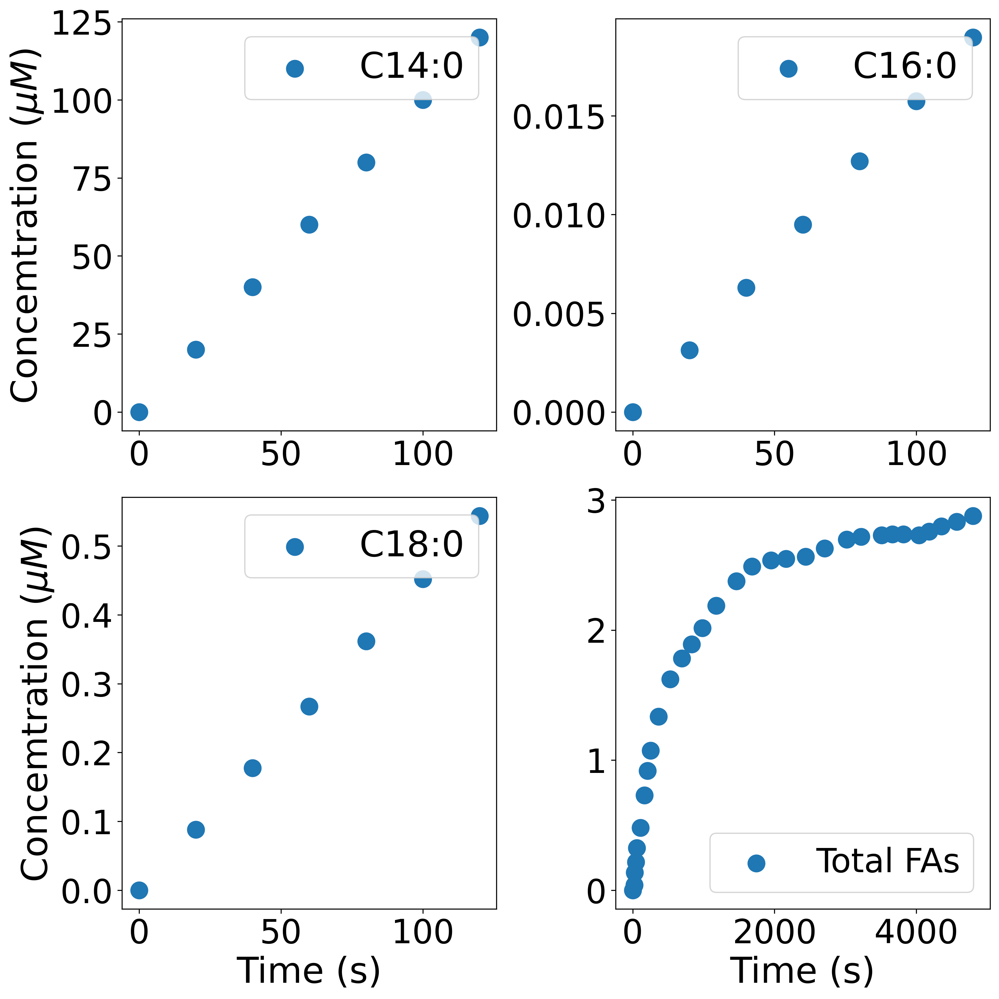

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(11, 11))
axs[0, 0].scatter(
    time_initial_phase,
    initial_phase_data.T[0],
    marker="o",
    linewidth=8,
    label="C14:0",
    
)
axs[0, 0].legend(loc="best", fontsize=28)
axs[0, 1].scatter(
    time_initial_phase,
    initial_phase_data.T[1],
    marker="o",
    linewidths=8,
    label="C16:0",
    
)
axs[0, 1].legend(loc="best", fontsize=28)
axs[1, 0].scatter(
    time_initial_phase,
    initial_phase_data.T[2],
    marker="o",
    linewidth=8,
    label="C18:0",
   
)
axs[1, 0].legend(loc="best", fontsize=28)
axs[1, 1].scatter(
     time_nefas1_simulation,
    total_nefas1,
    marker="o",
    linewidth=8,
    label="Total FAs",
   
)
axs[1, 1].legend(loc="best", fontsize=26)
for ax in axs[:, 0]:
    ax.set_ylabel("Concemtration ($\mu M$) ", fontsize=28)
for ax in axs[1, :]:
    ax.set_xlabel("Time (s)", fontsize=28)
for ax in axs.flatten():
    ax.tick_params(axis="both", labelsize=26)
# fig.suptitle("title", fontsize=20.0)
fig.tight_layout()

plt.savefig(RESULTS_DIR /"Data.pdf", dpi=300, bbox_inches="tight")


# plt.plot(time_interp, data_to_fit, "o-", linewidth=1)

# plt.xlabel("Time (s) ", fontsize=18)
# plt.ylabel("Concemtration ($\mu M$) ", fontsize=18)
# plt.title("Data in $\mu M$ ", fontsize=18)
# plt.xticks(size=18)
# plt.yticks(size=18)
# # plt.yscale("log")
# ax.legend(
#     ["C14", "C16", "C18"],
#     loc="upper left",
#     bbox_to_anchor=(1.1, 1),
#     borderaxespad=0,
#    ,
# )
# plt.tight_layout()
# plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
# plt.show()
fig.patch.set_alpha(0.0)
fig.tight_layout()
fig.savefig(RESULTS_DIR /"data_topolska.eps", dpi=300, bbox_inches="tight")

findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


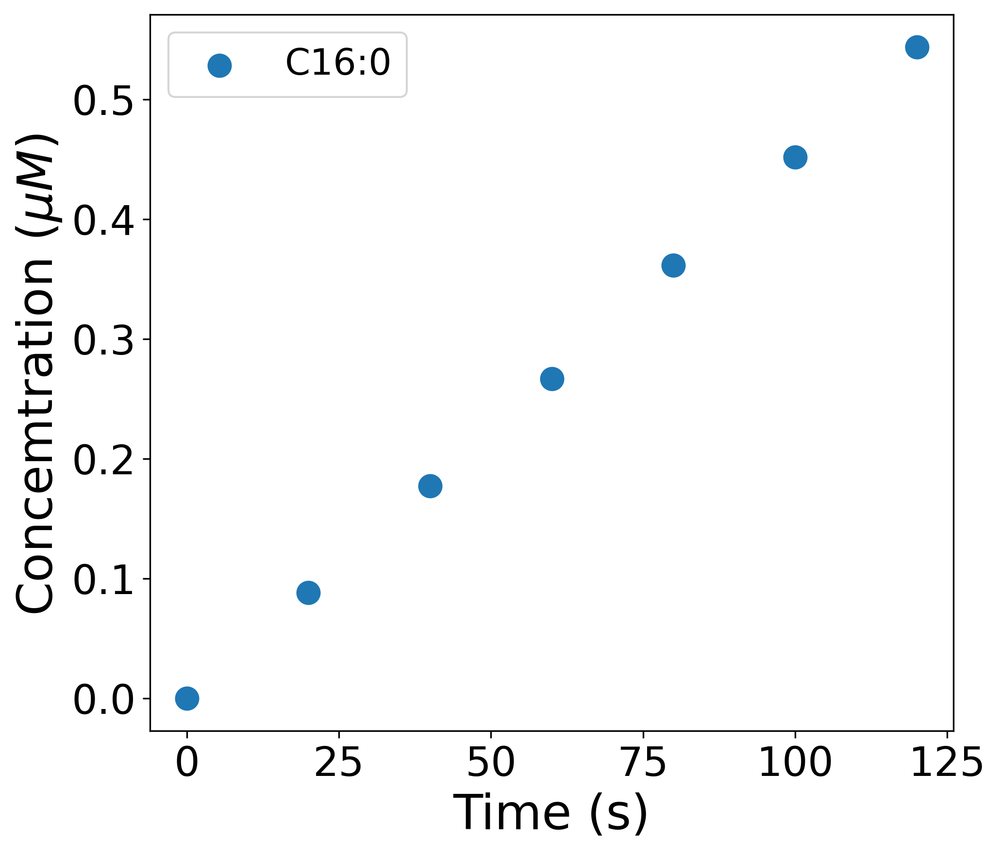

In [5]:
#labels1 = ["C14:0", "C16:0", "C18:0"]

fig, axs = plt.subplots(1, 1, figsize=(7,6))
# axs.scatter(
#     time_initial_phase,
#      initial_phase_data.T[1],
#     marker="*",
#     linewidths=6,
#     label ="C14:0"
# )
axs.scatter(
    time_initial_phase,
     initial_phase_data.T[2],
    marker="o",
    linewidths=6,
    label = "C16:0"
)
# axs[0].scatter(
#     time_initial_phase,
#      initial_phase_data.T[3],
#     marker="*",
#     linewidths=6,
#     label = "C18:0"
# )
axs.legend(loc="best", fontsize=18)
#fig.patch.set_alpha(0.0) # to make the axis transparent 
axs.legend(prop=dict(size=18))
#axs.set_title(" Initial phase data from Topolska et al. 2020", fontsize =24, fontname="serif", fontweight="bold",  pad=20)
axs.set_ylabel("Concemtration ($\mu M$) ", fontsize=24)
#fig.suptitle( " Initial phase data from Topolska et al. 2020", fontname="serif", fontweight="bold")
axs.set_xlabel("Time (s)", fontsize=24)

axs.tick_params(axis="both", labelsize=20)

#####


# axs[1].scatter(
#      time_nefas1_simulation,
#     total_nefas1,
#      marker= "*",
#     linewidth=6,
#     label="Total FAs",
#     #color="b",
# )
# axs[1].legend(loc="best", fontsize=20)
# axs[1].legend(prop=dict(size=20))

# #ax.set_title(" Total fatty acids from Topolska et al. 2020", fontsize =24,  fontname="serif", fontweight="bold", pad=20)
# #axs[1].set_ylabel("Concemtration ($\mu M$) ", fontsize=24)

# axs[1].set_xlabel("Time (s)", fontsize=20)
#  # to make the axis transparent 
# axs[1].tick_params(axis="both", labelsize=16)

# axs[0].text(-0.1, 1.1, string.ascii_lowercase[0], transform=axs[0].transAxes, 
#             size=20, weight='bold')
# axs[1].text(-0.1, 1.1, string.ascii_lowercase[1], transform=axs[1].transAxes, 
#             size=20, weight='bold')
# fig.suptitle("title", fontsize=20.0)
# fig.suptitle("title", fontsize=20.0)
fig.patch.set_alpha(0.0)
fig.tight_layout()
fig.savefig(RESULTS_DIR /"palmitic.eps", dpi=300, bbox_inches="tight")

# Fuction for simulations 

In [6]:
def plot_individual_time_course(
    compounds_to_plot: list[str],
    func: callable,
    model: callable,
    y0: list[float],
    max_time: float,
    ncp_list: list[float],
    par: dict[str, float],
    compounds: list[str],
    ncols: int,
    resizer=4,
    sharex=True,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):
    """
    required library: pandas, matplotlib, assimulo
    func = function that simulate the time course
    model =  system of differential equation to be integrated
    y0 = initial condition it can be either a list of float or np.1D.array
    max_time =  maximum time for simulation
    ncp_list = number of communication points
    compounds =  list of compounds to be plotted
    par =  dictionnay of string to float

    """
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    Comp = dict(zip(compounds, y))
    data = pd.DataFrame(Comp)
    data =data.rename(dict(enumerate(time)))

    nrows = ceil(len(compounds_to_plot) / ncols)

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )
    axes = axs.flat
    for n , ax in enumerate(axes):
        ax.text(-0.1, 1.1, string.ascii_lowercase[n], transform=ax.transAxes, 
            size=20, weight='bold')

    for ax, group in zip(axs.flatten(), compounds_to_plot):
        data.loc[:, group].plot(ax=ax, linewidth=5)
        ax.set_title(group, fontsize=28.0, fontname="serif", fontweight="bold")
        
        
    #         ax.set_ylabel(ylabel, fontsize=20)
    #         ax.set_xlabel(xlabel, fontsize=20.0)
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=24.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=24.0)
    for ax in axs.flatten():
        ax.tick_params(axis="both", labelsize=18)
    fig.patch.set_alpha(0.0) # to make the axis transparent 
    fig.suptitle(title, fontname="serif", fontweight="bold")

    fig.tight_layout()

    return fig, axs



In [7]:
def multi_plot_time_course(
    groups: list[list],
    func: callable,
    model: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    compounds: list[str],
    ncols: int,
    resizer=4,
    sharex=False,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):
    """
    required library: pandas, matplotlib, assimulo
    group = group of compounds to be plotted (just giving the oportunityto plot them together)
    func = function that simulate the time course
    model =  system of differential equation to be integrated
    y0 = initial condition it can be either a list of float or np.1D.array
    max_time =  maximum time for simulation
    ncp_list = number of communication points
    compounds =  list of compounds to be plotted
    par =  dictionnay of string to float

    """
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    Comp = dict(zip(compounds, y))
    data = pd.DataFrame(Comp)
    data =data.rename(dict(enumerate(time)))
   

    nrows = ceil(len(groups) / ncols)


    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )
    flat_axs = axs.flatten()
    #for i, axi in enumerate(flat_axs):
        # axi.text(-0.1, 1.1, string.ascii_lowercase[i], transform=axi.transAxes, 
        #     size=20, weight='bold')

    for ax, group in zip(axs.flatten(), groups):
        data.reindex(columns=group).plot(
            ax=ax, fontsize=18, linewidth=5,
        )
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=24.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=24.0)
    fig.patch.set_alpha(0.0)  # to make the axis transparent
    fig.suptitle(title, fontsize=16.0)

    fig.tight_layout()
    return fig, axs

In [8]:
def multi_plot_fluxes(
    fluxes_list: list[list[str]],
    model: callable,
    rates: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    ncols: int,
    resizer=4,
    sharex=True,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):

    """
    required library: pandas, matplotlib, assimulo
      flux_groups = list of list of  fluxes to be plotted, indeed the entrees should match the list of
    keys in the rates dictionnary
    model = system of ODE to be integrated(this function is dependent of the rate )
    rates = funtion that define the rates
    y0 = list/np.1D.array  of initial conditions
    par = dictionnary of parameters( dictionnay of string to float)
    max_time =  maximum time for simulation
    ncp_list = number of communication points to be passed to the integrator
    ncols  = number of colums for the subplots


    """

    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    fluxes = pd.DataFrame(rates(y, par))
    fluxes =fluxes.rename(dict(enumerate(time)))
    nrows = ceil(len(fluxes_list) / ncols)
    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )
    axes = axs.flat
    # for n , ax in enumerate(axes):
    #     ax.text(-0.1, 1.1, string.ascii_lowercase[n], transform=ax.transAxes, 
    #         size=20, weight='bold')
    for ax, group in zip(axs.flatten(), fluxes_list):
        fluxes.reindex(columns=group).plot(
            ax=ax, fontsize=18, linewidth=5,
        )
        ax.legend(prop=dict(size=18))
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=24.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=24.0)
    # for ax in axs.flatten():
    #     ax.tick_params(axis="both", labelsize=20)
    fig.patch.set_alpha(0.0) # to make the axis transparent 
    fig.suptitle(title, fontsize=28.0, fontname="serif", fontweight="bold")
    fig.tight_layout()
    return fig, axs


In [9]:
def plot_fluxes_individually(
    list_fluxes: list[str],
    model: callable,
    rates: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    ncols: int,
    resizer=4,
    sharey=False,
    sharex=True,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):

    """
    required library: pandas, matplotlib, assimulo
    list_fluxes = list of fluxes to be plotted, indeed the entrees should match the list of
    keys in the rates dictionnary
    model = system of ODE to be integrated(this function is dependent of the rate )
    rates = funtion that define the rates
    y0 = list/np.1D.array  of initial conditions
    par = dictionnary of parameters( dictionnay of string to float)
    max_time =  maximum time for simulation
    ncp_list = number of communication points to be passed to the integrator
    ncols  = number of colums for the subplots


    """

    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )

    y = y.T
    fluxes = pd.DataFrame(rates(y, par))
    fluxes =fluxes.rename(dict(enumerate(time)))

    nrows = ceil(len(list_fluxes) / ncols)

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharey=sharey,
        sharex=sharex,
        squeeze=False,
    )
    axes = axs.flat
    for n , ax in enumerate(axes):
        ax.text(-0.1, 1.1, string.ascii_lowercase[n], transform=ax.transAxes, 
            size=20, weight='bold')
    
    for ax, group in zip(axs.flatten(), list_fluxes):
        fluxes.loc[:, group].plot(ax=ax, linewidth=4)
        ax.set_title(group, fontsize=28.0)

    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=24.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=24.0)
    for ax in axs.flatten():
        ax.tick_params(axis="both", labelsize=14)
    fig.patch.set_alpha(0.0) # to make the axis transparent 
    fig.suptitle(title, fontsize=28.0, fontname="serif", fontweight="bold")
    fig.tight_layout()
    return fig, axs


## To generate Sobol sequences 

In [10]:
def generate_sobol_sequence(n, k, l_bounds=None, u_bounds =None ):
    """
    n: number of sample
    m:power
    l_bounds: list of lower bound for the parameter to sample of size n
    u_bounds: list of upper bound for the parameter to sample of size n
    Generate a Sobol sequence in the given dimension with n points.
    """
    sampler= qmc.Sobol(d=n, scramble=False)
    sample = sampler.random_base2(m=k)
    if l_bounds==None and u_bounds==None:
        return sample
    elif l_bounds!=None and u_bounds!=None:
        final_sample = qmc.scale(sample, l_bounds, u_bounds)
        return final_sample
    else:
        raise ValueError ("If the lower bound is given, the upper bound should also be given and conversely")

# Simulation of the model 

## First choice parameters 
We consider the scenario in which only three type of fatty acids could be produced, those are C14, C16 and C18. Therefore, all the $ka_i = 0$, $kd_1$ to $kd_5$ are all 0. The value of $\kappa$ was calculated by considering the quasi steady state of all enzyme species and the initial phase data from *Topolska et al*. 2020.

In [11]:
par = {
    "beta": 1e-01,
    "kappa": 1e-1,
    "delta": 3.4e-07,  #
    # "kd1": 0,
    # "kd2": 0,
    # "kd3": 0,
    # "kd4": 0,
    # "kd5": 0,
    "kd6": 0.56,
    "kd7": 0.014,  #
    "kd8": 10,
    "FASt": 0.153,
    "kf_CoA":1e-3,
    "kb_CoA":1e-1
}


## The initial conditions 

In the tracer experiment by *Topolska et al. 2020* to measure the t

According to *Topolska et al. 2020* A the malonyl-CoA that was used for this experiment was contaminated by acetyl-CoA and there we have to make the corrections for the right amount of each substrates used in this experiment. 
The main product of the de novo fatty acids synthesis which is C16:0 
The correction for the initial conditions for acetyl-CoA and malonyl-CoA was first tried by 

In [12]:
# list of time points to be considered by the integrator
ncp_list1 = [i for i in range(0, 120, 1)]
ncp_list2 = [i for i in range(0, 4800)]
ncp_list3 = [i for i in range(0, 10000)]
max_time3 =ncp_list3[-1]
max_time1 = ncp_list1[-1]
max_time2 = ncp_list2[-1]
init = np.zeros(n_compounds)
# init = 10*np.random.uniform(0,1,n_compounds)
time_initial_phase = initial_phase_data[:, 0]
y0_dict = dict(zip(compounds, init))

# modifying initial conditions
y0_dict["E"] =0.153
y0_dict["AcetylCoA"] = 50 +(80-22.04)
y0_dict["NADPH"] = 200
y0_dict["MalonylCoA"] = 22.04
# y0_dict["C4FA"] = 0.0
# y0_dict["C6FA"] = 0.0
# y0_dict["C8FA"] = 0.0
# y0_dict["C10FA"] = 0.0
# y0_dict["C12FA"] = 0.0
y0_dict["C14FA"] = 0.0
y0_dict["C16FA"] = 0.0
y0_dict["C18FA"] = 0.0
y0 = np.fromiter(y0_dict.values(), dtype=float)


# Vanilla model 

We select the parameter in the way that they are in agreement with the  assumptions of the model 

In [13]:
### First choice of the parameters

par_vanilla = {
    "beta": 1e-1,
    "kappa": 1e-1,
    "delta": 1e-6,  #
    # "kd1": 0,
    # "kd2": 0,
    # "kd3": 0,
    # "kd4": 0,
    # "kd5": 0,
    "kd6": 1,
    "kd7": 1,  #
    "kd8": 1,
    "kf_CoA":1e-1,
    "kb_CoA":5e-4
}

## Rapid binding assumption

In [14]:
 ## time to observe the rapid binding 
test_time = [i * 0.002 for i in range(0, 101)]
test_time = np.linspace(0,0.2,1000)
max_test_time = test_time[-1]


### Fluxes 

findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


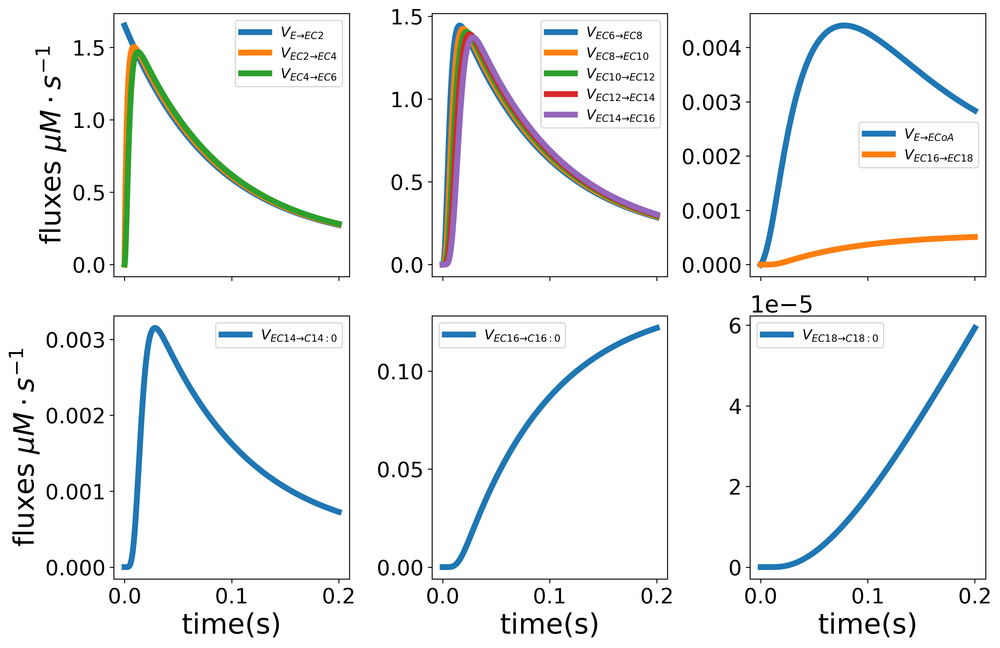

In [15]:
flux_groups = [
    ["AcetylCoA__EC2",
        "EC2__EC4",
        "EC4__EC6",
    ],
    [
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
    ],
    ["E__ECoA", "EC16__EC18",],
    [
        "EC14__C14FA",],
        ["EC16__C16FA",],
        ["EC18__C18FA",
    ],
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par_vanilla,
    max_time=max_test_time,
    ncp_list=test_time,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="fluxes $\mu M \cdot s^{-1}$",
)
legend1 = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$" ]
legend2 = [
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",]
legend3 = [ r"$V_{E \to ECoA}$", r"$V_{EC16 \to EC18}$"]
legend4 = [ r"$V_{EC14 \to C14:0}$"]
legend5 = [r"$V_{EC16 \to C16:0}$"]
legend6 = [r"$V_{EC18 \to C18:0}$"]


axs[0,0].legend(legend1, fontsize =12)
axs[0,1].legend(legend2,   fontsize =12)
axs[0,2].legend(legend3,   fontsize =12)
axs[1,0].legend(legend4, fontsize =12)
axs[1,1].legend(legend5,   fontsize =12)
axs[1,2].legend(legend6,   fontsize =12)
#axs[0,0].legend([r"$V_{EC2 \to EC4}$", r"$V_{EC4 \to EC6}$", r"$V_{EC6 \to EC8}$" ],  fontsize =20)
fig.savefig(RESULTS_DIR /"vanilla_fluxes_CoA.eps", dpi=300, bbox_inches="tight")

### Plot time course for vanilla model 

findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


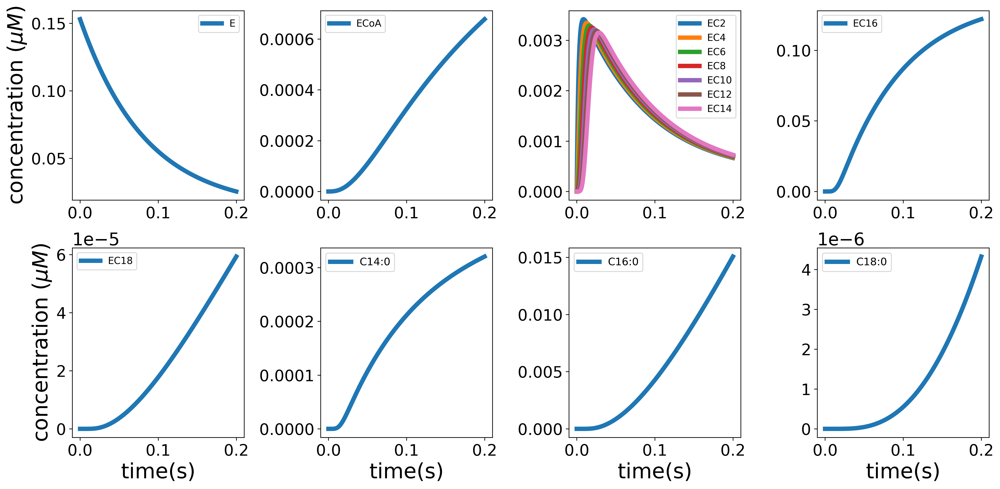

In [16]:
time_course = [
    # ["NADPH"],
    # ["AcetylCoA"],
    # ["MalonylCoA"],
    ["E"],
    ["ECoA",],
    ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    [ "EC16",],
     ["EC18"],
        ["C14FA"],
        ["C16FA"],
        ["C18FA"],
    ]




colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_test_time,
    ncp_list=test_time,
    par=par_vanilla,
    compounds=compounds,
    ncols=4,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
axs[-1,-3].legend(["C14:0"], fontsize =12)
axs[-1,-2].legend(["C16:0"],   fontsize =12)
axs[-1,-1].legend(["C18:0"],   fontsize =12)
fig.savefig(RESULTS_DIR /"vanilla_time_course_CoA.eps", dpi=300, bbox_inches="tight")

## Qualitative dynamics initial phase  

In [17]:
# this is the time to test  the inial phase 


time_linear_phase = [i*0.05 for i in range(0, 101)]
time_linear_phase= np.linspace(0,5,1000)
max_time_linear_phase = time_linear_phase[-1]


### Fluxes

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


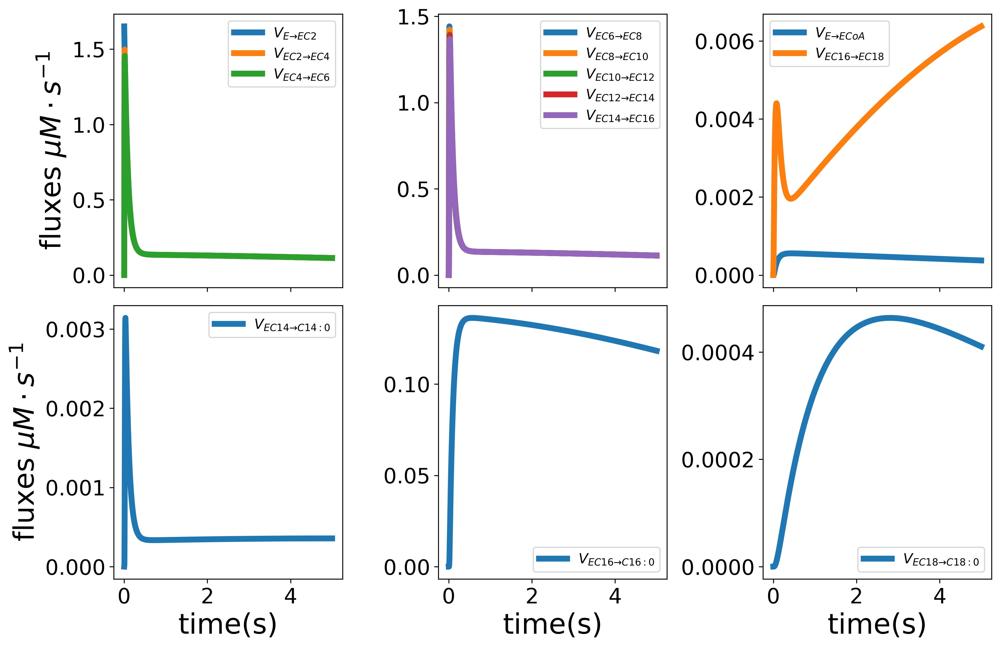

In [18]:
flux_groups = [
    ["AcetylCoA__EC2",
        "EC2__EC4",
        "EC4__EC6",
    ],
    [
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
    ],
    [ "EC16__EC18","E__ECoA"],
    [
        "EC14__C14FA",],
        ["EC16__C16FA",],
        ["EC18__C18FA",
    ],
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par_vanilla,
    max_time=max_time_linear_phase,
    ncp_list=time_linear_phase,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="fluxes $\mu M \cdot s^{-1}$",
)
legend1 = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$" ]
legend2 = [
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",]
legend3 = [ r"$V_{E \to ECoA}$", r"$V_{EC16 \to EC18}$"]
legend4 = [ r"$V_{EC14 \to C14:0}$"]
legend5 = [r"$V_{EC16 \to C16:0}$"]
legend6 = [r"$V_{EC18 \to C18:0}$"]


axs[0,0].legend(legend1, fontsize =12)
axs[0,1].legend(legend2,   fontsize =12)
axs[0,2].legend(legend3,   fontsize =12)
axs[1,0].legend(legend4, fontsize =12)
axs[1,1].legend(legend5,   fontsize =12)
axs[1,2].legend(legend6,   fontsize =12)
#axs[0,0].legend([r"$V_{EC2 \to EC4}$", r"$V_{EC4 \to EC6}$", r"$V_{EC6 \to EC8}$" ],  fontsize =20)
fig.savefig(RESULTS_DIR /"vanilla_fluxes_initial_CoA.eps", dpi=300, bbox_inches="tight")

### Time course 

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


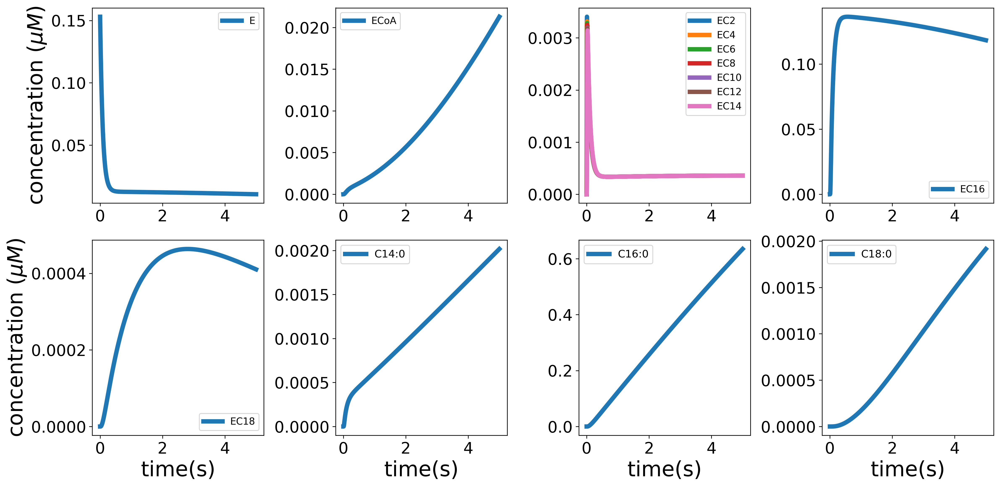

In [19]:
time_course = [
    # ["NADPH"],
    # ["AcetylCoA"],
    # ["MalonylCoA"],
    ["E"],
    ["ECoA",],
    ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    [ "EC16",],
     ["EC18"],
        ["C14FA"],
        ["C16FA"],
        ["C18FA"],
    ]



colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time_linear_phase,
    ncp_list=time_linear_phase,
    par=par_vanilla,
    compounds=compounds,
    ncols=4,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
axs[-1,-3].legend(["C14:0"], fontsize =12)
axs[-1,-2].legend(["C16:0"],   fontsize =12)
axs[-1,-1].legend(["C18:0"],   fontsize =12)
fig.savefig(RESULTS_DIR /"vanilla_time_course_initial_CoA.eps", dpi=300, bbox_inches="tight")

## Long phase 

In [20]:
# this is the time to test  the long


time_long_phase = [i*0.1 for i in range(0, 101)]
time_long_phase = np.linspace(0,50, 1000)
max_time_long_phase = time_long_phase[-1]


### Fluxes 

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


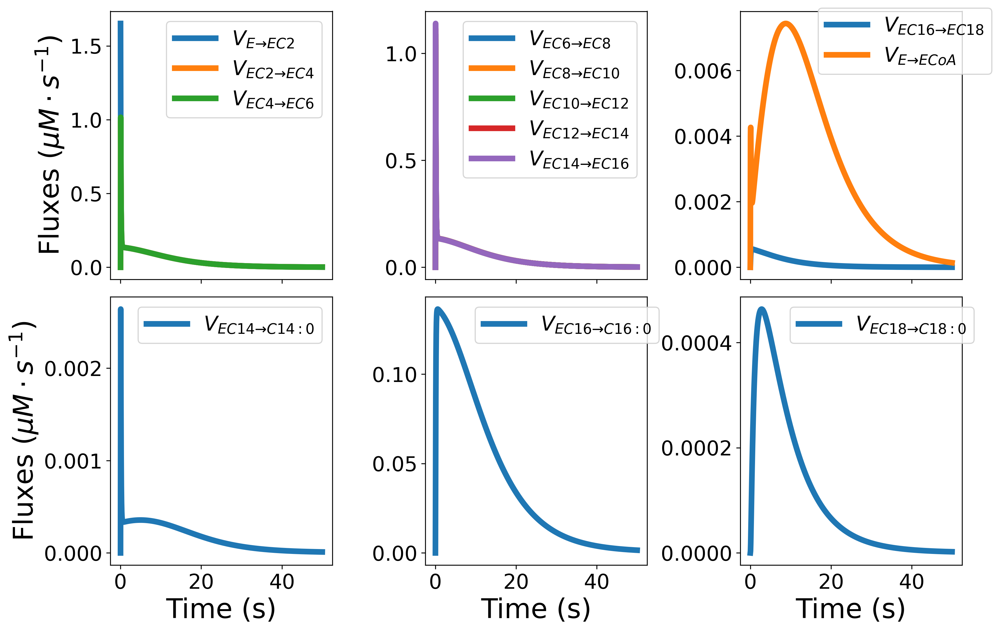

In [21]:
flux_groups = [
    ["AcetylCoA__EC2",
        "EC2__EC4",
        "EC4__EC6",
    ],
    [
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
    ],
    ["EC16__EC18","E__ECoA"],
    [
        "EC14__C14FA",],
        ["EC16__C16FA",],
        ["EC18__C18FA",
    ],
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par_vanilla,
    max_time=max_time_long_phase,
    ncp_list=time_long_phase,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="Time (s)",
    ylabel="Fluxes ($\mu M \cdot s^{-1}$)",
)
legend1 = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$" ]
legend2 = [
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",]
legend3 = [  r"$V_{EC16 \to EC18}$", r"$V_{E \to ECoA}$"]
legend4 = [ r"$V_{EC14 \to C14:0}$"]
legend5 = [r"$V_{EC16 \to C16:0}$"]
legend6 = [r"$V_{EC18 \to C18:0}$"]


axs[0,0].legend(legend1, fontsize =18)
axs[0,1].legend(legend2,   fontsize =18)
axs[0,2].legend(legend3,   fontsize =18,loc = "upper right", bbox_to_anchor=(1.18,1.05))
axs[1,0].legend(legend4, fontsize =18)
axs[1,1].legend(legend5,   fontsize =18,bbox_to_anchor=(1.1,1))
axs[1,2].legend(legend6,   fontsize =18,bbox_to_anchor=(1.1,1))
#axs[0,0].legend([r"$V_{EC2 \to EC4}$", r"$V_{EC4 \to EC6}$", r"$V_{EC6 \to EC8}$" ],  fontsize =20)
fig.savefig(RESULTS_DIR /"vanilla_fluxes_long_CoA.eps", dpi=300, bbox_inches="tight")

### Time course 

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


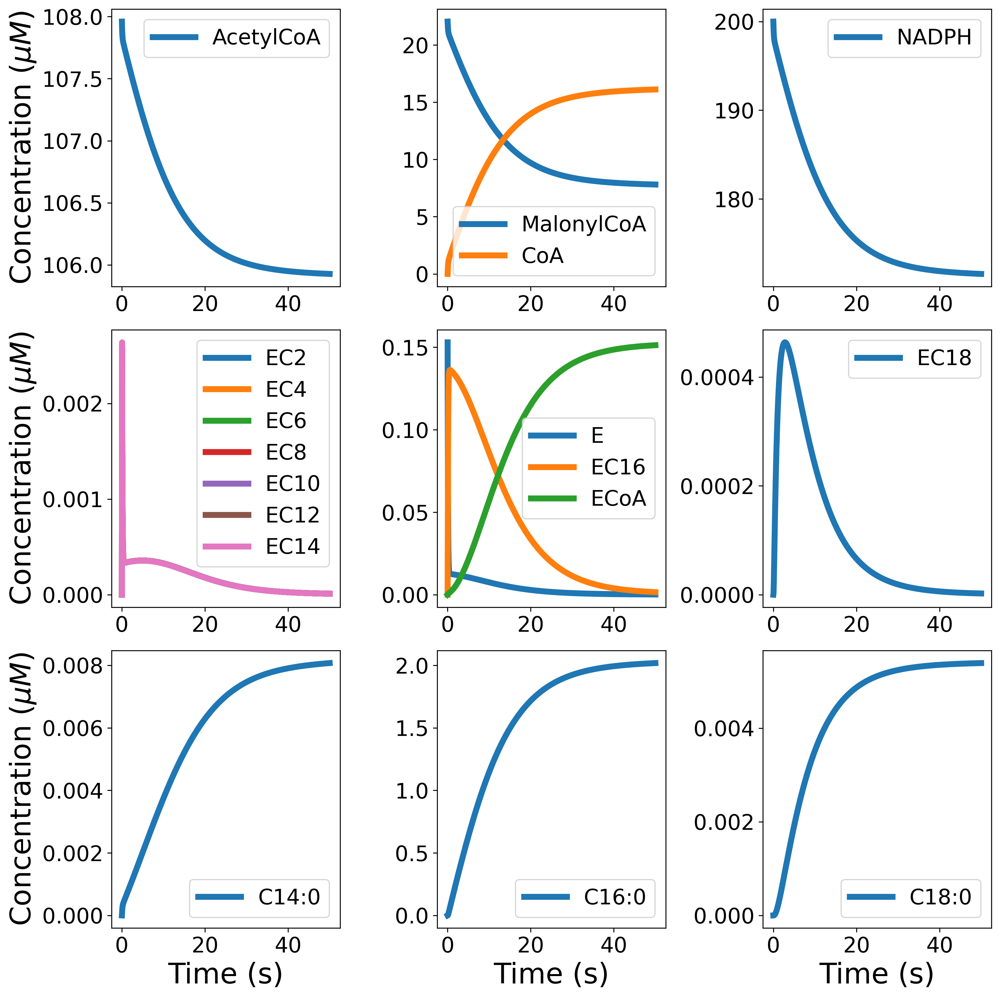

In [22]:
time_course = [
   
    ["AcetylCoA"],
    ["MalonylCoA", "CoA"],
    ["NADPH"],
    #["E","ECoA",],
    [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    ["E", "EC16","ECoA"],
     ["EC18"],
        ["C14FA"],
        ["C16FA"],
        ["C18FA"],
        
    ]

colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time_long_phase,
    ncp_list=time_long_phase,
    par=par_vanilla,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)
for ax in axs.flatten():
    ax.legend(fontsize =18)

axs[-1,-3].legend(["C14:0"], fontsize =18)
axs[-1,-2].legend(["C16:0"],   fontsize =18)
axs[-1,-1].legend(["C18:0"],   fontsize =18)

fig.savefig(RESULTS_DIR /"vanilla_time_course_long_CoA.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


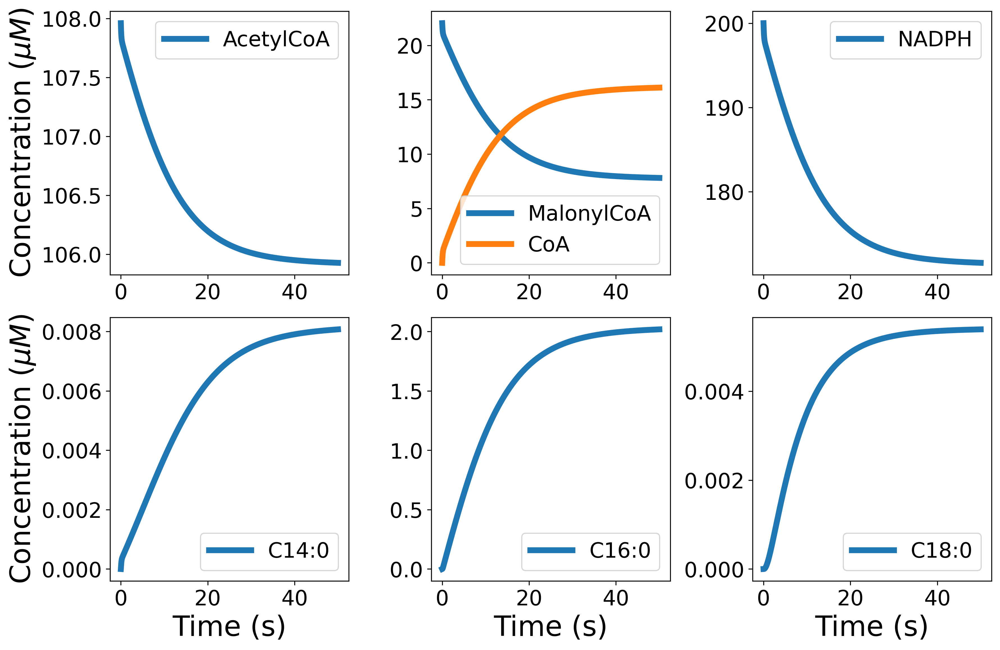

In [23]:
time_course = [
   
    ["AcetylCoA"],
    ["MalonylCoA", "CoA"],
    ["NADPH"],
    #["E","ECoA",],
    # [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    # ["E", "EC16","ECoA"],
    #  ["EC18"],
        ["C14FA"],
        ["C16FA"],
        ["C18FA"],
        
    ]

colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time_long_phase,
    ncp_list=time_long_phase,
    par=par_vanilla,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)
for ax in axs.flatten():
    ax.legend(fontsize =18)

axs[-1,-3].legend(["C14:0"], fontsize =18)
axs[-1,-2].legend(["C16:0"],   fontsize =18)
axs[-1,-1].legend(["C18:0"],   fontsize =18)

fig.savefig(RESULTS_DIR /"vanilla_sub_prod_time_course_CoA.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


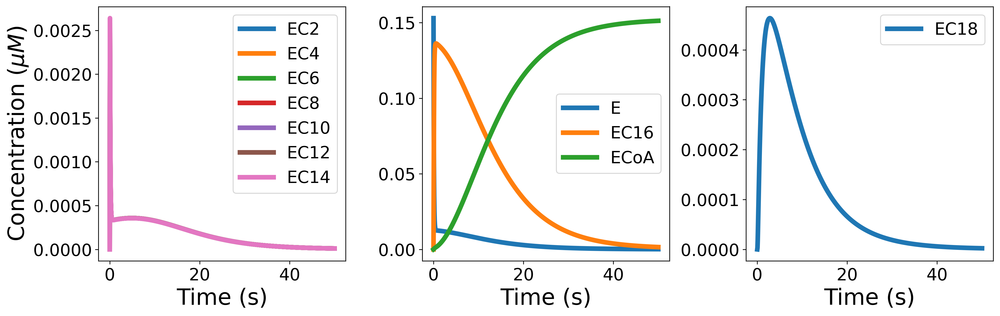

In [24]:
time_course = [
   
    # ["AcetylCoA"],
    # ["MalonylCoA", "CoA"],
    # ["NADPH"],
    # ["E","ECoA",],
    [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    ["E", "EC16","ECoA"],
     ["EC18"],
        # ["C14FA"],
        # ["C16FA"],
        # ["C18FA"],
        
    ]

colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time_long_phase,
    ncp_list=time_long_phase,
    par=par_vanilla,
    compounds=compounds,
    ncols=3,
    resizer=5,
    sharey=False,
    title=None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)
for ax in axs.flatten():
    ax.legend(fontsize =18)
axs[0,0].legend(fontsize =18,loc = "upper right", bbox_to_anchor=(1,1.))
# axs[-1,-3].legend(["C14:0"], fontsize =18)
# axs[-1,-2].legend(["C16:0"],   fontsize =18)
# axs[-1,-1].legend(["C18:0"],   fontsize =18)

fig.savefig(RESULTS_DIR /"vanilla_enz_time_course_CoA.eps", dpi=300, bbox_inches="tight")

# @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

## Range in which some parameters can be found

we vary the value of $\beta$ and $\kappa$ to see how the fit is sensitive to the value of these parameters.

- varying $\beta$ betwwen $1e-2$ and $1e3$, we can conclude that any value of $\beta$ in this range give a good fit. The same constat applies the value of $\kappa$ between $5e-3$ and $1e2$.
- We therefore choose the value of $\beta$ and $\kappa$ to be respectively $1e-1$ and $1e-2$



# Interpolation to have more points 

One can skip this step by setting the *number_of_points* to be equal to the number of points in the original data set.

#

In [25]:
number_of_points  =7

time_interp = np.linspace(
    0, time_initial_phase[-1],number_of_points 
)  # 7


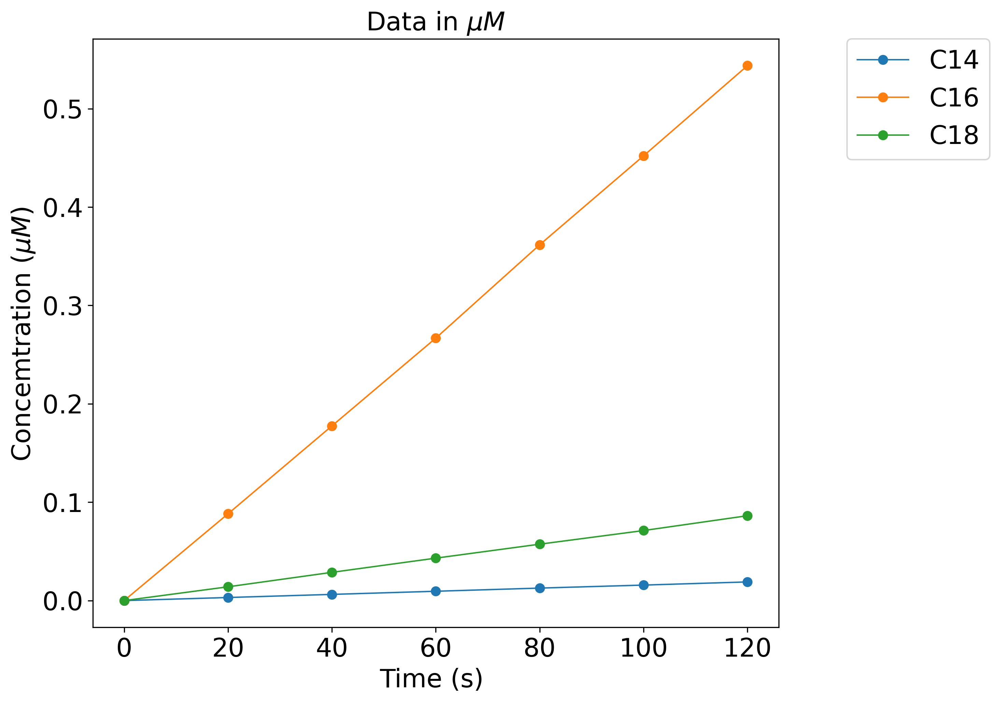

In [26]:
# use of lagrange interporlation to create more data point linearly

lagrange_interpolation_C14 = lagrange(time_initial_phase,  data_initial_phase[:, 0])
lagrange_interpolation_C16 = lagrange(time_initial_phase,  data_initial_phase[:, 1])
lagrange_interpolation_C18 = lagrange(time_initial_phase,  data_initial_phase[:, 2])

C14_data = lagrange_interpolation_C14(time_interp)
C16_data = lagrange_interpolation_C16(time_interp)
C18_data = lagrange_interpolation_C18(time_interp)

data_to_fit = np.array([C14_data, C16_data, C18_data]).T


fig, ax = plt.subplots(figsize=(10, 7))
plt.plot(time_interp, data_to_fit, "o-", linewidth=1)

plt.xlabel("Time (s) ", fontsize=18)
plt.ylabel("Concemtration ($\mu M$) ", fontsize=18)
plt.title("Data in $\mu M$ ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()


In [27]:
# residual function to be passed to lmfit library
# The function *fatty_acid_of_interest* solves the system and only returns  C14, C16 and C18.

# This residual function can oly be used for fitting the inital phase


def residual(parameters, max_time, time, data):
    #y0[1] = parameters["y0_mal"].value
    # print(y0)
    model = fatty_acid_of_interest(
        system, parameters, y0, max_time=max_time, ncp_list=time
    )
    res = (model - data).ravel()

    return res



par_to_fit = Parameters()
par_to_fit.add("beta", value=1e-1, vary =False)
par_to_fit.add("kappa", value=1e-1,min =0)
par_to_fit.add("delta", value=1.17e-06, min =0, max = 1e-1)
# par_to_fit.add("kd1", value=0, min =0)
# par_to_fit.add("kd2", value=0, min =0)
# par_to_fit.add("kd3", value=0, min =0)
# par_to_fit.add("kd4", value=0, min =0)
# par_to_fit.add("kd5", value=0.0, min =0)
par_to_fit.add("kd6", value=1, min=0,)
par_to_fit.add("kd7", value=0.03, min =0)
par_to_fit.add("kd8", value=1, vary =False)
par_to_fit.add("kf_CoA", value=0.1, min =0)
par_to_fit.add("kb_CoA", value=0.1, min =0)

In [28]:
# lower_bounds = [0, 0, 0] # dimension of the 
# upper_bounds = [10, 10, 10]
# name_params = [
# #"beta",
# "kappa",
# "delta",
# "kd6",
# #"kd7",
# #"kd8",
# # "kf_CoA",
# # "kb_CoA", 
#     ]
# # number of parameter 
# n = len(name_params)
# # Power of 2 as we are using sobol generator sequence (by setting m=3 the sample size will 2^3 =8)
# m=2




# list_parameters =[]
# list_of_list_values = generate_sobol_sequence(n, m, l_bounds= lower_bounds, u_bounds=upper_bounds).tolist()
# list_chisq = []
# result_fitting_list =[]
# list_of_list_values.pop(0)
# list_of_list_values

In [29]:
# i=0
# for values in list_of_list_values:
#     parameters_dict= dict(zip(name_params,values))
#     par_to_fit = Parameters()
#     par_to_fit.add("beta", value=0.1, vary =False)
#     par_to_fit.add("kappa", value=parameters_dict["kappa"],min =0,  max =1)
#     par_to_fit.add("delta", value=parameters_dict["delta"], min =0, max = 1e-1)
#     par_to_fit.add("kd6", value=parameters_dict["kd6"], min=0,)
#     par_to_fit.add("kd7", value=0.03, vary =False)
#     par_to_fit.add("kd8", value=1, vary =False )
#     par_to_fit.add("kf_CoA", value=0, min =0, max =1)
#     par_to_fit.add("kb_CoA", value=0, min =0 , max =1)
  
#     result_topolska = minimize(
#     residual,
#     par_to_fit,
#     args=(time_interp[-1], time_interp, data_to_fit),
#     method="leastsquare",
#     )
      
#     list_chisq.append(result_topolska.chisqr)
#     i=i+1
#     print(i)


In [30]:
# list_root_mean_square = list(np.sqrt(np.array(list_chisq)/len(name_params)))
# min_chisq = min(list_root_mean_square)
# index_min_chisq = list_root_mean_square.index(min_chisq)
# print(max(list_root_mean_square))
# print(f"The minimal element is {min_chisq}, and it is at index {index_min_chisq}")

# parameters_best = dict(zip(name_params, list_of_list_values[index_min_chisq]))
# parameters_best

In [31]:
# parameters_dict= dict(zip(name_params,values))
# par_to_fit = Parameters()
# par_to_fit.add("beta", value=0.1,vary =False)
# par_to_fit.add("kappa", value=parameters_best["kappa"],min =0, max =1)
# par_to_fit.add("delta", value=parameters_best["delta"], min =0, max = 1e-1)
# par_to_fit.add("kd6", value=parameters_best["kd6"], min=0, max =10)
# par_to_fit.add("kd7", value=0.03, vary =False)
# par_to_fit.add("kd8", value=1, vary =False)
# par_to_fit.add("kf_CoA", value=0, vary =False)
# par_to_fit.add("kb_CoA", value=0, vary =False)

In [32]:
# final = data_to_fit + result_topolska.residual.reshape(data_to_fit.shape)
# final.shape

In [33]:
# report_fit(result_topolska)


In [34]:
time_long_simulation = np.linspace(0, 4801,200)



The initial phase parameter is unable to reproduce the total concentration of NEFAs.

### Fitting the total fatty acids for the long run time 

# Dual fitting 

In [35]:
def residual_two(parameters, max_time1, time1, data1, max_time2, time2, data2):
    #y0[1] = parameters["y0_mal"].value
    #print(y0)
    model1 = fatty_acid_of_interest(system, parameters, y0, max_time = max_time1 , ncp_list = time1)
    model2= total_fatty_acid(system, parameters, y0, max_time = max_time2 , ncp_list = time2)
    res1 =(model1 - data1).ravel()
    res2 = (model2 - data2).ravel()
    
    return np.concatenate((res1, res2)) 



## Leastsquare dual fitting 

In [36]:
lower_bounds = [0, 0] # dimension of the 
upper_bounds = [10, 10]
name_params = [
#"kd6",, auto_add_to_figure=True,
"kf_CoA",
"kb_CoA"
    ]
# number of parameter 
n = len(name_params)
# Power of 2 as we are using sobol gea  la dynamique, on peut noter
m =1

list_parameters =[]
list_of_list_values = generate_sobol_sequence(n, m, l_bounds= lower_bounds, u_bounds=upper_bounds).tolist()
list_chisq = []
result_fitting_list =[]
beta= []
kappa = []
delta = [] 
kd6 = [] 
kd8 = []  
kf= []
kb =[]




In [37]:
par_initial_phase={'beta': 0.04345734538274404,
 'kappa': 0.11647817468522687,
 'delta': 1.3021869110230178e-06,
 'kd6': 9.99999997374512,
 'kd7': 0.03,
 'kd8': 0.7000678571704833,
 'y0_mal': 22.04}

In [38]:
lower_bounds = [0, 0,] # dimension of the 
upper_bounds = [10, 10]
name_params = [
# "beta",   
# "kd6",
# "kd8",
"kf_CoA",
"kb_CoA"
    ]
# number of parameter 
n = len(name_params)
# Power of 2 as we are using sobol gea  la dynamique, on peut noter
m =4

list_parameters =[]
list_of_list_values = generate_sobol_sequence(n, m, l_bounds= lower_bounds, u_bounds=upper_bounds).tolist()
list_chisq = []
result_fitting_list =[]
beta= []
kappa = []
delta = [] 
kd6 = [] 
kd8 = []  
kf= []
kb =[]



i=1
for values in list_of_list_values:
    parameters_dict= dict(zip(name_params,values))

    par_dual_lsq = Parameters()
    par_dual_lsq.add("beta", value=par_initial_phase["beta"], vary =False)
    par_dual_lsq.add("kappa", value=par_initial_phase["kappa"], vary= False)
    par_dual_lsq.add("delta", value= par_initial_phase["delta"],   vary =False)
    par_dual_lsq.add("kd6", value=par_initial_phase["kd6"], vary =False)
    par_dual_lsq.add("kd7", value= 0.03, vary =False)
    par_dual_lsq.add("kd8", value= par_initial_phase["kd8"],vary =False)
    par_dual_lsq.add("kf_CoA", value=parameters_dict["kf_CoA"], min=0, max =1)
    par_dual_lsq.add("kb_CoA", value=parameters_dict["kb_CoA"], min=0, max =1)
    par_dual_lsq.add("y0_mal", value=22.04, vary =False)
    
    list_parameters.append(parameters_dict)
    result_two_lsq = minimize(residual_two, par_dual_lsq, 
                          args=(time_interp[-1],
                                time_interp, data_to_fit,
                                max_time_nefas1_simulation, 
                                time_nefas1_simulation ,
                                total_nefas1),
                          method="leastsquare")
    
    list_chisq.append(result_two_lsq.chisqr)
    par_temp = dict(result_two_lsq.params.valuesdict())
    beta.append(par_temp["beta"])
    kappa.append(par_temp["kappa"])
    delta.append(par_temp["delta"])
    kd6.append(par_temp["kd6"])
    #kd7.append(par_temp["kd7"])
    kd8.append(par_temp["kd8"]) 
    kf.append(par_temp["kf_CoA"])
    kb.append(par_temp["kb_CoA"])
    i=i+1
    print(i)


2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17


In [39]:
par_initial_phase["beta"]

0.04345734538274404

In [40]:
list_root_mean_square = list(np.sqrt(list_chisq))
min_chisq = min(list_root_mean_square)
index_min_chisq = list_root_mean_square.index(min_chisq)
print(max(list_root_mean_square))
print(f"The minimal element is {min_chisq}, and it is at index {index_min_chisq}")

parameters_best = dict(zip(name_params, list_of_list_values[index_min_chisq]))
parameters_best

0.5213417596740652
The minimal element is 0.521341733796614, and it is at index 0


{'kf_CoA': 0.0, 'kb_CoA': 0.0}

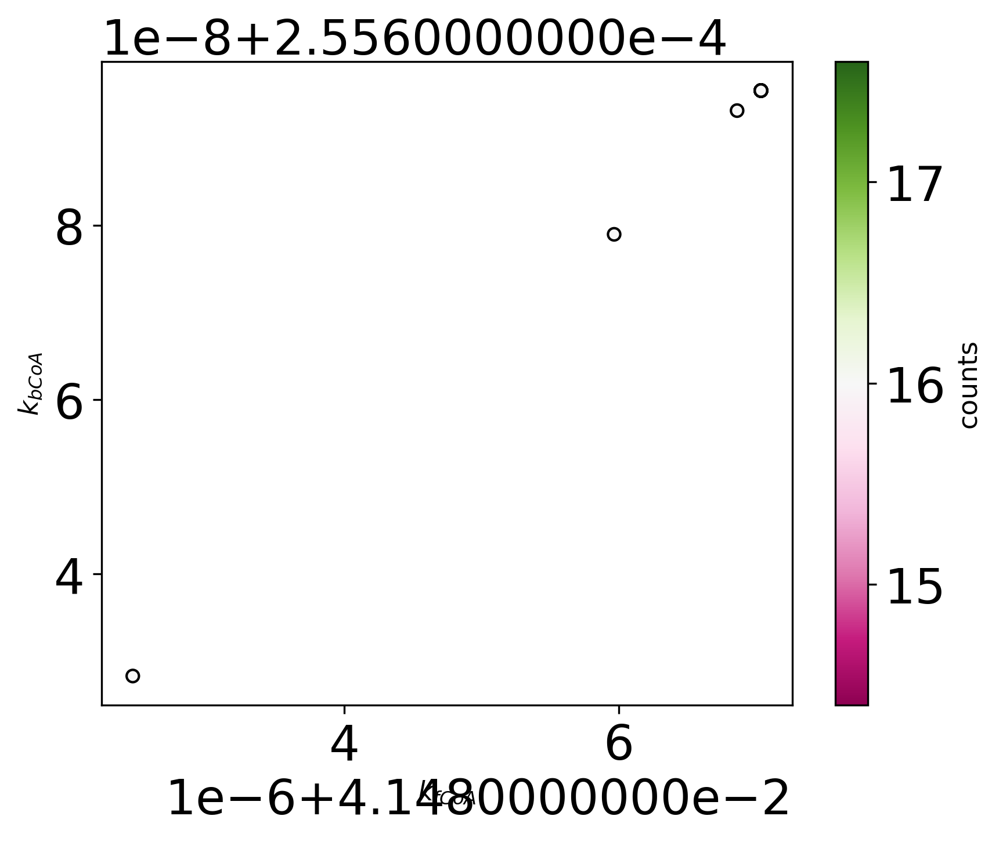

In [41]:
round_list_mean_square = [ round(elem, 3) for elem in list_root_mean_square]
round_list_kfCoA = [ round(elem, 10) for elem in kf]
round_list_kbCoA = [ round(elem, 10) for elem in kb]

x = round_list_kfCoA.copy()
y = round_list_kbCoA.copy()
z = round_list_mean_square .copy()

# compute the entry counts
import numpy as np
u,c = np.unique(z, return_counts=True)

# color according to the counts
color = [c[np.where(u==z[i])][0] for i in range(len(z))]

# plot the data (with the function you already used)
plt.scatter(x, y, s=np.array(z)*50, c=color, cmap='PiYG', marker='o', edgecolors='black', linewidth=1,  alpha=1)
# for i, txt in enumerate(z):
#     plt.annotate(txt, (x[i], y[i]), fontsize =10)
plt.xlabel(r"$k_{fCoA}$")
plt.ylabel(r"$k_{bCoA}$")
plt.colorbar(label='counts')

In [42]:
key_dict_par_list = [
                    #r"$\beta$",
                    #  r"$\kappa$", 
                    #  r"$\delta$", 
                  #r"$k_{d6}$", 
                    #r"$k_{d8}$", 
                    r"$k_{fCoA}$",
                    r"$k_{bCoA}$",
                     "RMSE"
                     ]
values_dict_par_list = [
                        #beta,
                        #kappa, 
                        #delta, 
                        #kd6,
                        #kd8, 
                        round_list_kfCoA,
                        round_list_kbCoA,                 
                        round_list_mean_square
                        ]

parameter_data_dict = dict(zip(key_dict_par_list, values_dict_par_list))

parameter_chisq_data = pd.DataFrame.from_dict(parameter_data_dict,orient='index').transpose()
parameter_chisq_data 

,$k_{fCoA}$,$k_{bCoA}$,RMSE
0,0.041486,0.000256,0.521
1,0.041487,0.000256,0.521
2,0.041487,0.000256,0.521
3,0.041487,0.000256,0.521
4,0.041487,0.000256,0.521
5,0.041487,0.000256,0.521
6,0.041487,0.000256,0.521
7,0.041487,0.000256,0.521
8,0.041487,0.000256,0.521
9,0.041487,0.000256,0.521


In [43]:
selected_data = parameter_chisq_data[parameter_chisq_data ["RMSE"]<0.53]

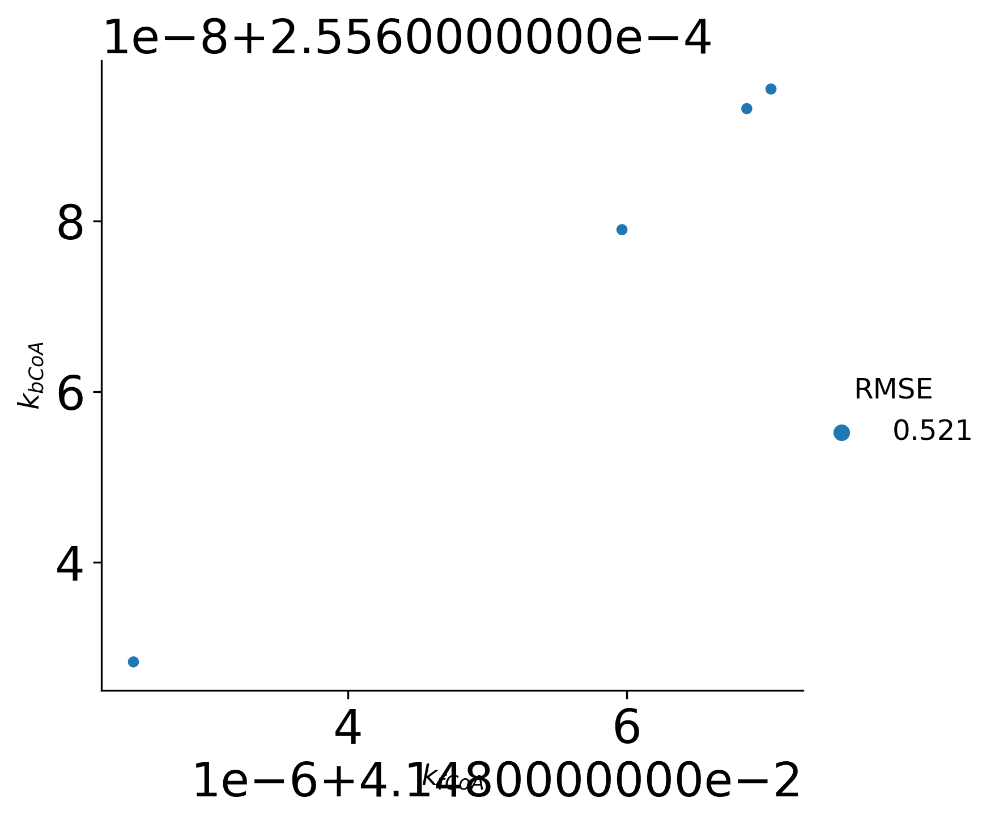

In [44]:
rc={'axes.labelsize': 12, 'font.size': 12, 'legend.fontsize': 12, 'axes.titlesize': 12}
plt.rcParams.update(**rc)
g =sns.relplot(data=parameter_chisq_data,
                x=parameter_chisq_data[r"$k_{fCoA}$"],
                y =parameter_chisq_data[r"$k_{bCoA}$"],
                hue= "RMSE",
                s=np.flip(np.array(z)*50),
                #kind='kde',
                palette="tab10")
# g.map_diag(plt.hist, edgecolor='black')
# g.map_offdiag(plt.scatter, edgecolor='black')
# #g.map(plt.scatter, s=50, edgecolor="black")


#g.add_legend()




g.savefig(RESULTS_DIR /"pairgrid_CoA.eps", dpi=300, bbox_inches="tight")

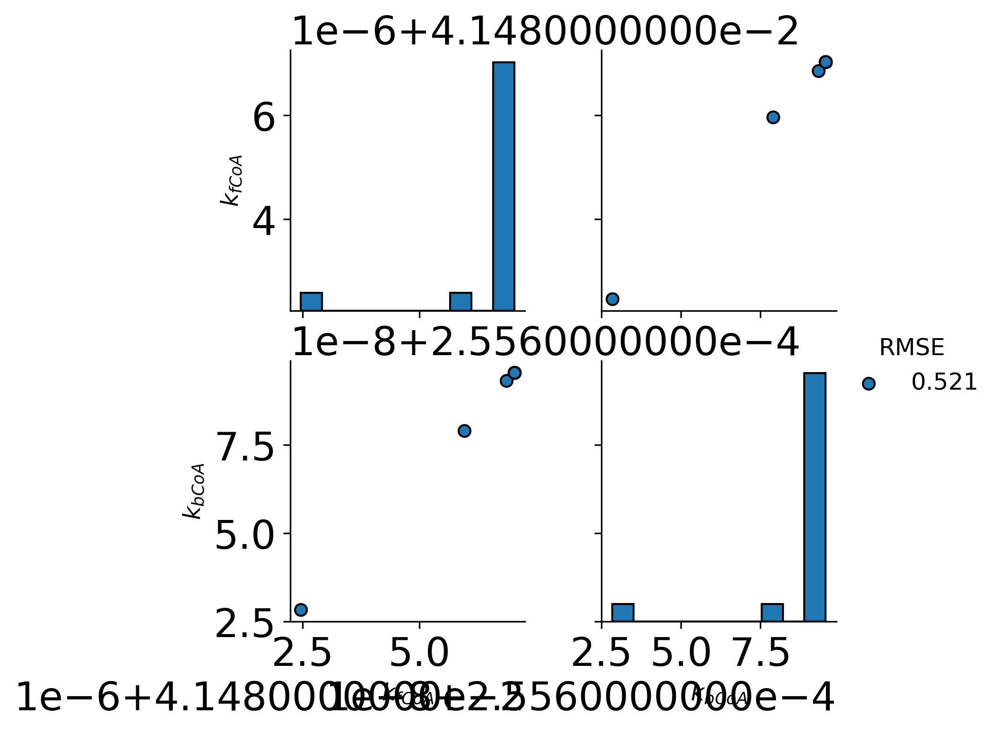

In [45]:
rc={'axes.labelsize': 12, 'font.size': 12, 'legend.fontsize': 12, 'axes.titlesize': 12}
plt.rcParams.update(**rc)
g =sns.PairGrid(
               parameter_chisq_data ,
                hue= "RMSE",
                palette="tab10",
            
                )
g.map_diag(plt.hist, edgecolor='black')
g.map_offdiag(plt.scatter, edgecolor='black')
#g.map(plt.scatter, s=50, edgecolor="black")


g.add_legend()




g.savefig(RESULTS_DIR /"pairgrid_only_min_CoA.pdf", dpi=300, bbox_inches="tight")

In [46]:
rc={'axes.labelsize': 12, 'font.size': 11, 'legend.fontsize': 11.0, 'axes.titlesize':12}
plt.rcParams.update(**rc)
plt.rcParams.update({'figure.dpi': '300'})
plt.rcParams.update({
    "font.family": "serif",   # specify font family here
    "font.serif": ["Times"],  # specify font here
    "font.size":11}) 

/tmp/ipykernel_14145/4198545805.py:3: MatplotlibDeprecationWarning: Axes3D(fig) adding itself to the figure is deprecated since 3.4. Pass the keyword argument auto_add_to_figure=False and use fig.add_axes(ax) to suppress this warning. The default value of auto_add_to_figure will change to False in mpl3.5 and True values will no longer work in 3.6.  This is consistent with other Axes classes.
  ax = Axes3D(fig, auto_add_to_figure=True,)
/tmp/ipykernel_14145/4198545805.py:23: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


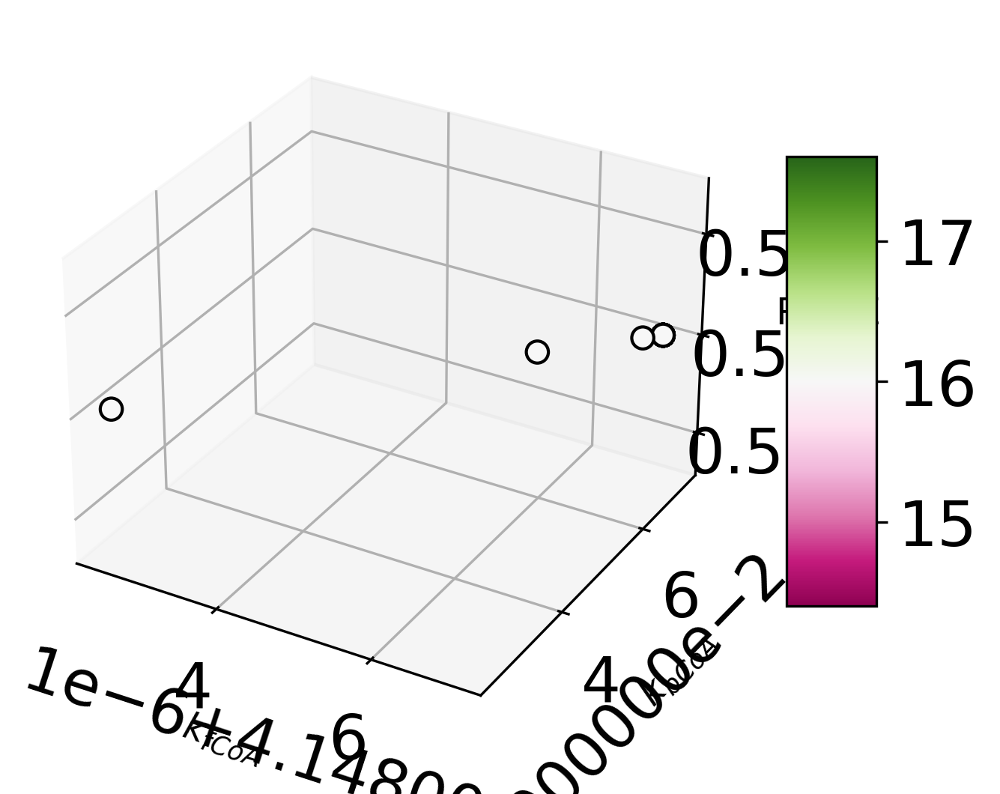

In [47]:
cmap = ListedColormap(sns.color_palette("husl", 256).as_hex())
fig = plt.figure(figsize=(4,4))
ax = Axes3D(fig, auto_add_to_figure=True,)
fig.add_axes(ax)
x =round_list_kfCoA.copy()
y = round_list_kfCoA.copy()
z = round_list_mean_square .copy()

# compute the entry counts

u,c = np.unique(z, return_counts=True)

# color according to the counts
color = [c[np.where(u==z[i])][0] for i in range(len(z))]
surf =ax.scatter3D(x, y, z, s=50, c=color, cmap='PiYG', marker='o', edgecolors='black', linewidth=1, alpha=1)
ax.set_xlabel(r'$k_{fCoA}$')
ax.set_ylabel(r'$k_{bCoA}$')
ax.set_zlabel('RMSE')
fig.colorbar(surf, shrink=0.5, aspect=5)

#fig.patch.set_alpha(0.0)
#fig.tight_layout()
fig.show()

In [48]:
par_dual_lsq = Parameters()
par_dual_lsq.add("beta", value=par_initial_phase["beta"], vary =False)
par_dual_lsq.add("kappa", value=par_initial_phase["kappa"],vary =False)
par_dual_lsq.add("delta", value= par_initial_phase["delta"],   vary =False)
par_dual_lsq.add("kd6", value=par_initial_phase["kd6"],  vary =False)
par_dual_lsq.add("kd7", value= 0.03, vary =False)
par_dual_lsq.add("kd8", value=par_initial_phase["kd8"],vary =False)
par_dual_lsq.add("kf_CoA", value=parameters_best["kf_CoA"], min=0,max =1 )
par_dual_lsq.add("kb_CoA", value=parameters_best["kb_CoA"], min=0,max =1)
par_dual_lsq.add("y0_mal", value=22.04, vary =False)



In [49]:
result_two_lsq = minimize(residual_two, par_dual_lsq, 
                          args=(time_interp[-1],
                                time_interp, data_to_fit,
                                max_time_nefas1_simulation, 
                                time_nefas1_simulation ,
                                total_nefas1),
                          method="leastsquare")
# final_two = data2 + result.residual.reshape(data2.shape)
# final_two.shape


In [50]:
par_fitting_two_lsq = dict(result_two_lsq.params.valuesdict())
par_fitting_two_lsq


{'beta': 0.04345734538274404,
 'kappa': 0.11647817468522687,
 'delta': 1.3021869110230178e-06,
 'kd6': 9.99999997374512,
 'kd7': 0.03,
 'kd8': 0.7000678571704833,
 'kf_CoA': 0.041485966570145194,
 'kb_CoA': 0.0002556790310327961,
 'y0_mal': 22.04}

# Very important 

{'beta': 0.04345734538274404,
 'kappa': 0.11647817468522687,
 'delta': 1.3021869110230178e-06,
 'kd6': 9.99999997374512,
 'kd7': 0.03,
 'kd8': 0.7000678571704833,
 'kf_CoA': 0.04148645847277749,
 'kb_CoA': 0.00025568688030791487,
 'y0_mal': 22.04}

In [51]:
RMSE =np.sqrt(result_two_lsq.chisqr)
RMSE

0.521341733796614

In [52]:
report_fit(result_two_lsq)

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 32
    # data points      = 52
    # variables        = 2
    chi-square         = 0.27179720
    reduced chi-square = 0.00543594
    Akaike info crit   = -269.205025
    Bayesian info crit = -265.302537
[[Variables]]
    beta:    0.04345735 (fixed)
    kappa:   0.1164782 (fixed)
    delta:   1.302187e-06 (fixed)
    kd6:     10 (fixed)
    kd7:     0.03 (fixed)
    kd8:     0.7000679 (fixed)
    kf_CoA:  0.04148597 +/- 0.00165723 (3.99%) (init = 0)
    kb_CoA:  2.5568e-04 +/- 2.5844e-05 (10.11%) (init = 0)
    y0_mal:  22.04 (fixed)
[[Correlations]] (unreported correlations are < 0.100)
    C(kf_CoA, kb_CoA) = 0.939


In [53]:
rc={'axes.labelsize': 12, 'font.size': 11, 'legend.fontsize': 11.0, 'axes.titlesize':12}
plt.rcParams.update(**rc)
plt.rcParams.update({'figure.dpi': '300'})
plt.rcParams.update({
    "font.family": "serif",   # specify font family here
    "font.serif": ["Times"],  # specify font here
    "font.size":11}) 


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


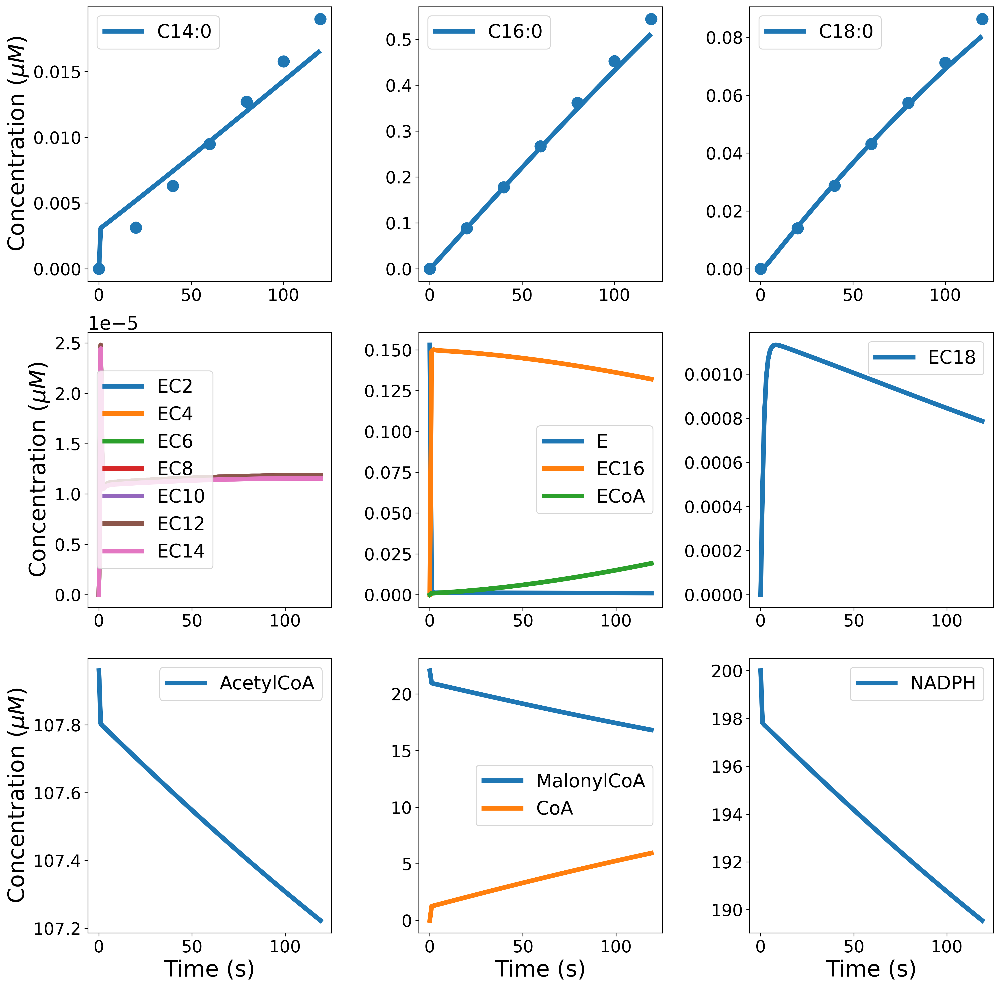

In [54]:
time_course = [[
        "C14FA"],
        ["C16FA"],
        ["C18FA"],
    # ["NADPH"],
    # ["AcetylCoA"], 
    # ["MalonylCoA"],
    ["CoA"],
    #["E",],
    ["E","EC16","ECoA"],
   
    ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"], 
    ["EC18"],
    
    
    
]




time_course = [
        ["C14FA"],
        ["C16FA"],
        ["C18FA"],
    #["E","ECoA",],
    [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    ["E", "EC16","ECoA"],
     ["EC18"],
    ["AcetylCoA"],
    ["MalonylCoA", "CoA"],
    ["NADPH"]
        
    ]




fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par_fitting_two_lsq,
    compounds=compounds,
    ncols=3,
    resizer=5,
    sharey=False,
    title= None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids= total_fatty_acid(system,par_fitting_two_lsq , y0, max_time = time_nefas1_simulation, ncp_list = ncp_list2)
for ax in axs.flatten():
    ax.legend(fontsize =20)
axs[0,-3].legend(["C14:0"], fontsize =20)
axs[0,-2].legend(["C16:0"],   fontsize =20)
axs[0,-1].legend(["C18:0"],   fontsize =20)

for i in range(3):
    axs[0, i].scatter(time_initial_phase, data_initial_phase[:, i],marker = "o", linewidths =7 )
fig.savefig(RESULTS_DIR /"time_coures_initial_phase_final_fitting_CoA1.eps", dpi=300, bbox_inches="tight")


findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


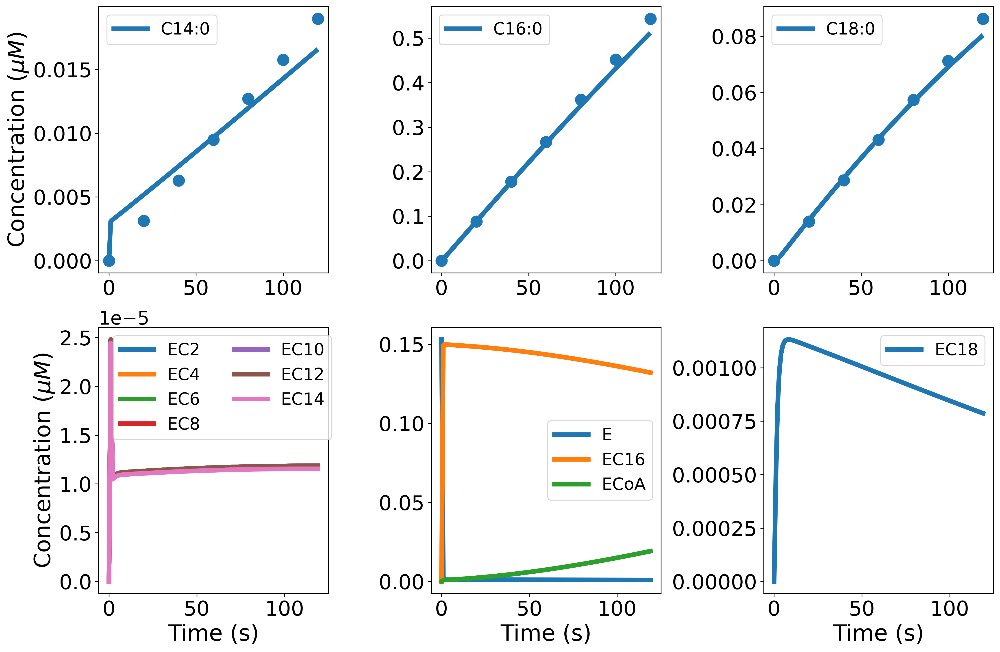

In [55]:





time_course = [
        ["C14FA"],
        ["C16FA"],
        ["C18FA"],
    #["E","ECoA",],
    [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    ["E", "EC16","ECoA"],
     ["EC18"],
    # ["AcetylCoA"],
    # ["MalonylCoA", "CoA"],
    # ["NADPH"]
        
    ]




fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par_fitting_two_lsq,
    compounds=compounds,
    ncols=3,
    resizer=5,
    sharey=False,
    title= None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids= total_fatty_acid(system,par_fitting_two_lsq , y0, max_time = time_nefas1_simulation, ncp_list = ncp_list2)
for ax in axs.flatten():
    ax.tick_params(axis="both", labelsize=22)
    ax.legend(fontsize =18)
axs[0,-3].legend(["C14:0"], fontsize =18)
axs[0,-2].legend(["C16:0"],   fontsize =18)
axs[0,-1].legend(["C18:0"],   fontsize =18)
axs[1,0].legend( loc = "upper right", bbox_to_anchor=(1.05,1),ncol=2, fontsize =18)
for i in range(3):
    axs[0, i].scatter(time_initial_phase, data_initial_phase[:, i],marker = "o", linewidths =7 )
t = axs[1,0].yaxis.get_offset_text()
t.set_size(20)
fig.tight_layout()
fig.savefig(RESULTS_DIR /"time_coures_initial_phase_final_fitting_CoA.eps", dpi=300, bbox_inches="tight")


ValueError: 'f' is not a valid value for color

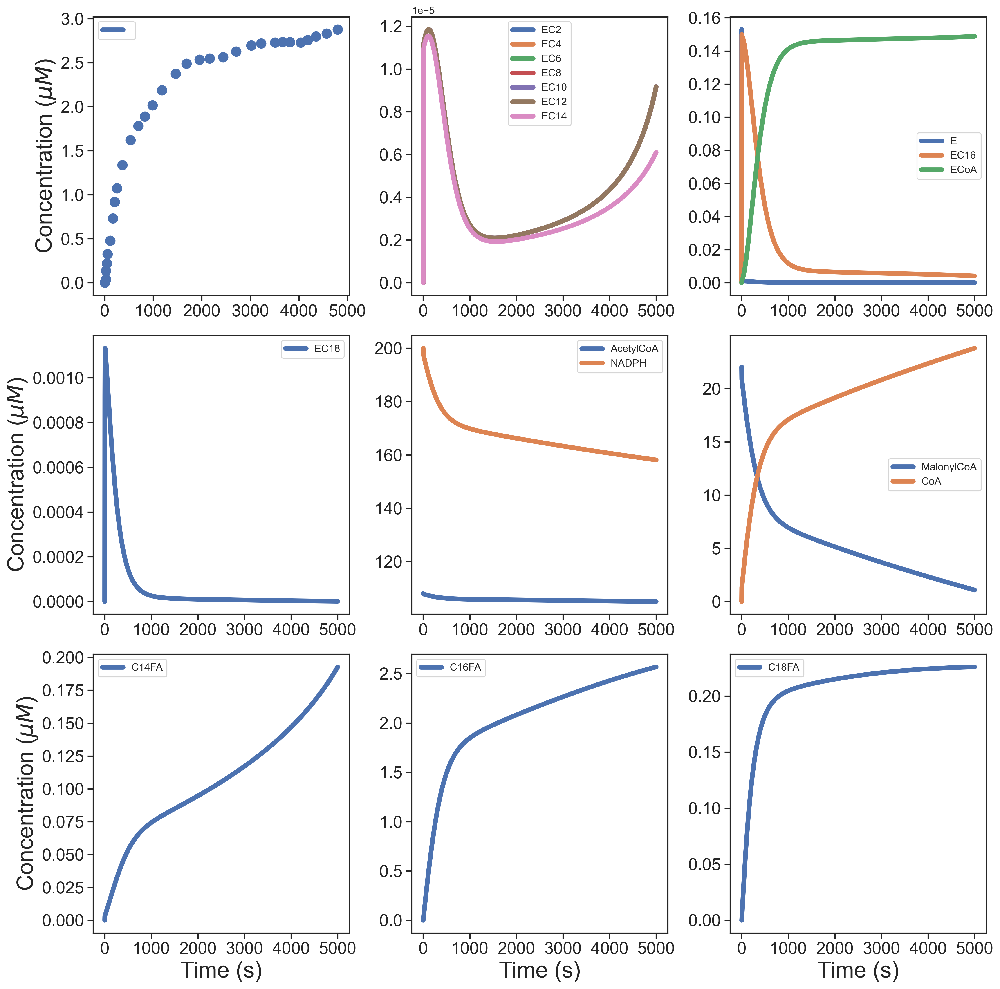

In [109]:
from tkinter.ttk import Style
T = np.linspace(0,5000,2000)
max_T = T[-1]
time_course2 = [ [ ""],
        
    #["E","ECoA",],
    [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    ["E", "EC16","ECoA"],
     ["EC18"],
    ["AcetylCoA","NADPH"],
    ["MalonylCoA", "CoA"],
   ["C14FA"],
    ["C16FA"],
    ["C18FA"],
        
    ]
fig, axs = multi_plot_time_course(
    groups=time_course2,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_T,
    ncp_list=T ,
    par=par_fitting_two_lsq ,
    compounds=compounds,
    ncols=3,
    resizer=5,
    sharey=False,
    title= None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)

# adding data to a particular graph
all_fatty_acids= total_fatty_acid(system,par_fitting_two_lsq , y0, max_time = max_time_nefas1_simulation, ncp_list = time_nefas1_simulation)

axs[0, 0].scatter(time_nefas1_simulation, total_nefas1, marker = "o", linewidths =5, label="Total FAs")
axs[0, 0].plot(time_nefas1_simulation, all_fatty_acids, linewidth=4, label = "Simulation", color = colors[1][1])
# axs[0, 0].legend(
#     [
#     "Simulations",
#     "Data"
#     ],)

for ax in axs.flatten():
    ax.legend(fontsize =20)
axs[2,-3].legend(["C14:0"], fontsize =20)
axs[2,-2].legend(["C16:0"],   fontsize =20)
axs[2,-1].legend(["C18:0"],   fontsize =20)
fig.savefig(RESULTS_DIR /"time_course_final_fitting_CoA12.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


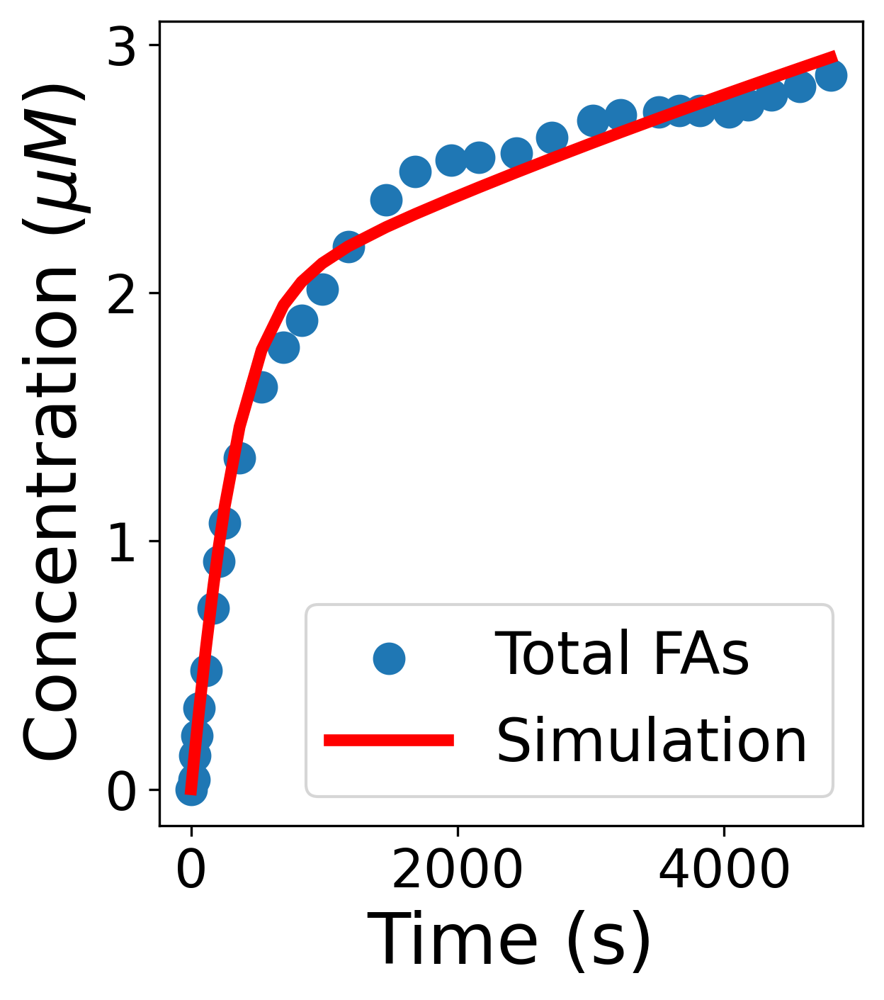

In [57]:
from tkinter.ttk import Style
T = np.linspace(0,5000,2000)
max_T = T[-1]
time_course2 = [ 
         [ ""],
        #  ["C16FA"],
        #  ["C14FA", "C18FA"],
        #  ["E", "EC16","ECoA"],
         #["AcetylCoA","NADPH"],
        #  ["MalonylCoA", "CoA"],
    #["E","ECoA",],
    # [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    #  ["EC18"],
    
    
        
    ]
fig, axs = multi_plot_time_course(
    groups=time_course2,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_T,
    ncp_list=T ,
    par=par_fitting_two_lsq ,
    compounds=compounds,
    ncols=1,
    resizer=5,
    sharey=False,
    title= None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)

# adding data to a particular graph
all_fatty_acids= total_fatty_acid(system,par_fitting_two_lsq , y0, max_time = max_time_nefas1_simulation, ncp_list = time_nefas1_simulation)

axs[0, 0].scatter(time_nefas1_simulation, total_nefas1, marker = "o", linewidths =5, label="Total FAs")
axs[0, 0].plot(time_nefas1_simulation, all_fatty_acids, linewidth=4, label = "Simulation", color = colors[1][1])
# axs[0, 0].legend(
#     [
#     "Simulations",
#     "Data"
#     ],)

for ax in axs.flatten():
    ax.legend(fontsize =20)
# axs[0,-2].legend(["C16:0"], fontsize =20)
# axs[0,-1].legend(["C14:0","C18:0"],   fontsize =20)
# axs[2,-1].legend(["C18:0"],   fontsize =20)
fig.savefig(RESULTS_DIR /"fitting_total.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


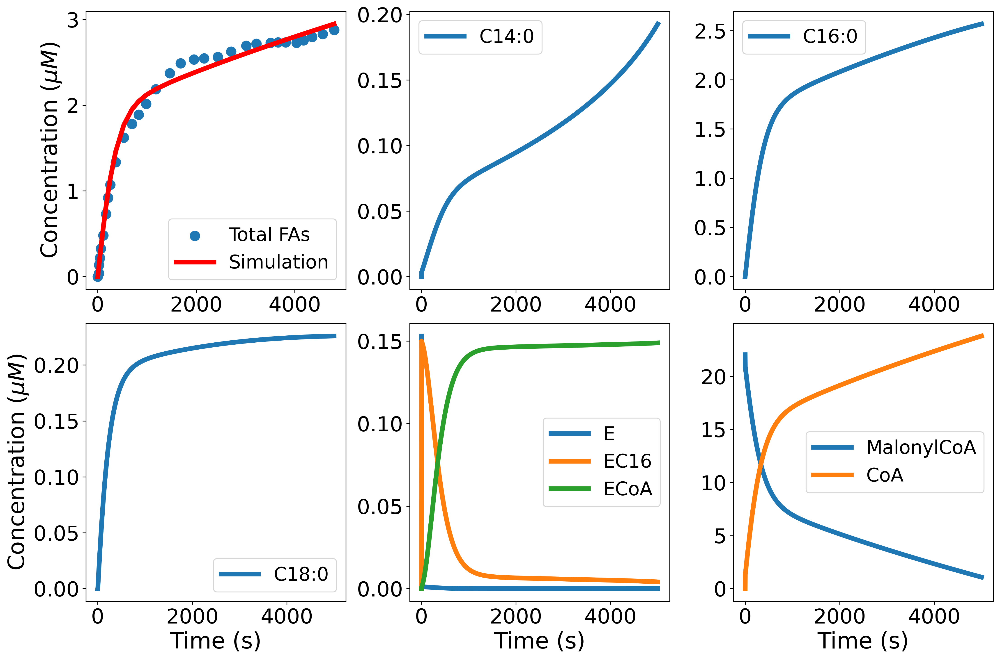

In [58]:
from tkinter.ttk import Style
T = np.linspace(0,5000,2000)
max_T = T[-1]
time_course2 = [ 
                [""],
         ["C14FA"],
         ["C16FA"],
         ["C18FA"],
         ["E", "EC16","ECoA"],
         ["MalonylCoA", "CoA"],
         #["AcetylCoA","NADPH"],
         
    #["E","ECoA",],
    # [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    #  ["EC18"],
    
    
        
    ]
fig, axs = multi_plot_time_course(
    groups=time_course2,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_T,
    ncp_list=T ,
    par=par_fitting_two_lsq ,
    compounds=compounds,
    ncols=3,
    resizer=5,
    sharey=False,
    title= None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)

# adding data to a particular graph
all_fatty_acids= total_fatty_acid(system,par_fitting_two_lsq , y0, max_time = max_time_nefas1_simulation, ncp_list = time_nefas1_simulation)

axs[0, 0].scatter(time_nefas1_simulation, total_nefas1, marker = "o", linewidths =5, label="Total FAs")
axs[0, 0].plot(time_nefas1_simulation, all_fatty_acids, linewidth=5, label = "Simulation", color = colors[1][1])
axs[0, 0].legend(
    [
    "Simulations",
    "Data"
    ],)

for ax in axs.flatten():
    ax.legend(fontsize =20)
    ax.tick_params(axis="both", labelsize=22)
axs[0,-2].legend(["C14:0"], fontsize =20)
axs[0,-1].legend(["C16:0"],   fontsize =20)
axs[1,-3].legend(["C18:0"],   fontsize =20)
t = axs[1,2].yaxis.get_offset_text()
t.set_size(20)
fig.savefig(RESULTS_DIR /"time_course_final_fitting_CoA1.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


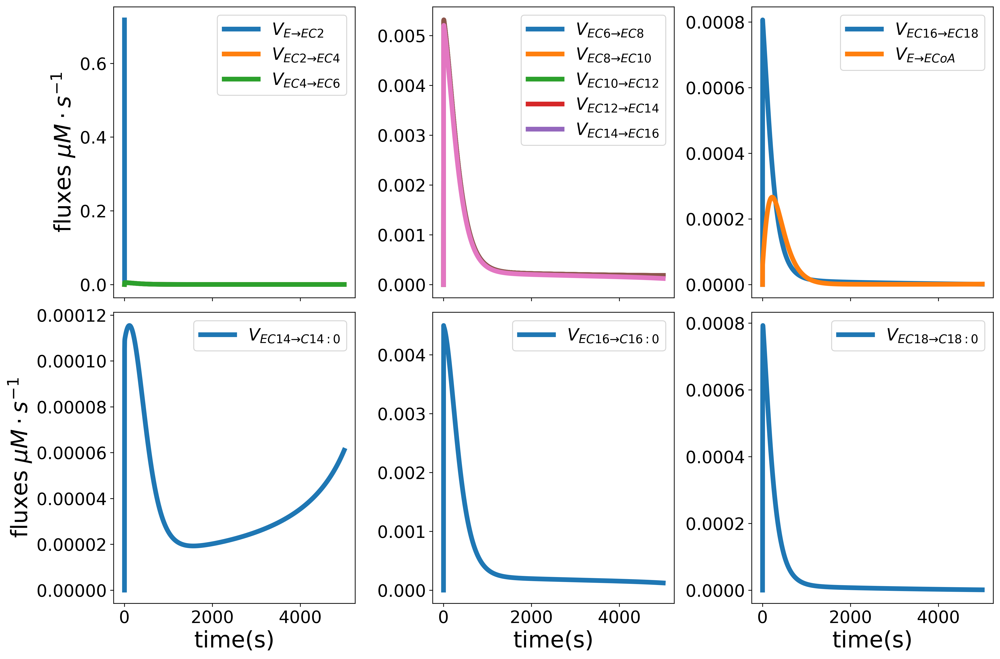

In [59]:
flux_groups = [
    ["AcetylCoA__EC2",
        "EC2__EC4",
        "EC4__EC6",
    ],
    ["EC2__EC4",
        "EC4__EC6",
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
    ],
    ["EC16__EC18","E__ECoA"],
    [
        "EC14__C14FA",],
        ["EC16__C16FA",],
        ["EC18__C18FA",
    ],
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par_fitting_two_lsq,
    max_time=max_T,
    ncp_list=T,
    ncols=3,
    resizer=5,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="fluxes $\mu M \cdot s^{-1}$",
)
legend1 = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$" ]
legend2 = [
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",]
legend3 = [  r"$V_{EC16 \to EC18}$", r"$V_{E \to ECoA}$"]
legend4 = [ r"$V_{EC14 \to C14:0}$"]
legend5 = [r"$V_{EC16 \to C16:0}$"]
legend6 = [r"$V_{EC18 \to C18:0}$"]


axs[0,0].legend(legend1, fontsize =18)
axs[0,1].legend(legend2,   fontsize =18)
axs[0,2].legend(legend3,   fontsize =18)
axs[1,0].legend(legend4, fontsize =18)
axs[1,1].legend(legend5,   fontsize =18)
axs[1,2].legend(legend6,   fontsize =18)
#axs[0,0].legend([r"$V_{EC2 \to EC4}$", r"$V_{EC4 \to EC6}$", r"$V_{EC6 \to EC8}$" ],  fontsize =20)
fig.savefig(RESULTS_DIR /"Flux_final_fitting_CoA.eps", dpi=300, bbox_inches="tight")

## Monte carlo markov chain for parameter space exploration 

In [60]:
par_dual_emcee = Parameters()
par_dual_emcee.add("beta", value=par_fitting_two_lsq["beta"], min =0, max =11)
par_dual_emcee.add("kappa", value=par_fitting_two_lsq["kappa"], min=0, max =11)
par_dual_emcee.add("delta", value= par_fitting_two_lsq["delta"],   min=0, max =11)
par_dual_emcee.add("kd6", value=par_fitting_two_lsq["kd6"], min =0, max =10)
par_dual_emcee.add("kd7", value= 0.03, vary =False)
par_dual_emcee.add("kd8", value= par_fitting_two_lsq["kd8"], min =0, max =10)
par_dual_emcee.add("kf_CoA", value=par_fitting_two_lsq["kf_CoA"], min=0,max =1 )
par_dual_emcee.add("kb_CoA", value=par_fitting_two_lsq["kb_CoA"], min=0,max =1)
par_dual_emcee.add("y0_mal", value=22.04, vary =False)

In [61]:
result_two_emcee = minimize(
    residual_two,
    par_dual_emcee,
    args=(time_interp[-1],
    time_interp, data_to_fit,
    max_time_nefas1_simulation, 
    time_nefas1_simulation ,
    total_nefas1),
   method="emcee",
    nan_policy="omit",
    burn=100,
    workers=20,
    steps=10,
    thin=20,
    is_weighted=False,
    progress=True,
)




  0%|          | 0/10 [00:00<?, ?it/s]/home/chilperic/anaconda3/envs/fatty-acids/lib/python3.10/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in double_scalars
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 10/10 [01:30<00:00,  9.09s/it]


IndexError: cannot do a non-empty take from an empty axes.

In [62]:
names_columns = [r"$\beta$", r"$\kappa$", r"$\delta$", r"$k_{d6}$", r"$k_{d8}$", r"$k_{fCoA}$",  r"$k_{bCoA}$"] 

In [63]:
data_to_plot = result_two_emcee.flatchain.drop(labels='__lnsigma', axis=1).set_axis(names_columns, axis=1, inplace=False)
data_to_plot

NameError: name 'result_two_emcee' is not defined

In [ ]:
rc={'axes.labelsize': 24, 'font.size': 15, 'legend.fontsize': 26.0, 'axes.titlesize': 15}
plt.rcParams.update(**rc)
g= sns.pairplot(data_to_plot, corner=True, diag_kind="kde", )
g.map_lower(sns.kdeplot, levels=4, color=".2")
g.savefig(RESULTS_DIR /"emcee_CoA_parameters.pdf", bbox_inches='tight')

NameError: name 'data_to_plot' is not defined

In [64]:
g.savefig(RESULTS_DIR /"emcee_CoA_parameters.eps", bbox_inches='tight')

In [65]:
rc={'axes.labelsize': 12, 'font.size': 11, 'legend.fontsize': 11.0, 'axes.titlesize':12}
plt.rcParams.update(**rc)
plt.rcParams.update({'figure.dpi': '300'})
plt.rcParams.update({
    "font.family": "serif",   # specify font family here
    "font.serif": ["Times"],  # specify font here
    "font.size":11}) 


In [66]:
g= sns.pairplot(result_two_emcee.flatchain, corner=True, diag_kind="kde",  height=3)
g.map_lower(sns.kdeplot, levels=4, color=".2")
g.fig.set_size_inches(20,20)


NameError: name 'result_two_emcee' is not defined

In [ ]:

report_fit(result_two_emcee)


NameError: name 'result_two_emcee' is not defined

In [67]:
par_fitting_two_emcee = dict(result_two_emcee.params.valuesdict())
par_fitting_two_emcee

NameError: name 'result_two_emcee' is not defined

In [ ]:
fatty_acids = fatty_acid_of_interest(
    system,
    par=par_fitting_two_emcee ,
    y0=y0,
    max_time=time_initial_phase[-1],
    ncp_list=time_initial_phase,
)



NameError: name 'par_fitting_two_emcee' is not defined

NameError: name 'fatty_acids' is not defined

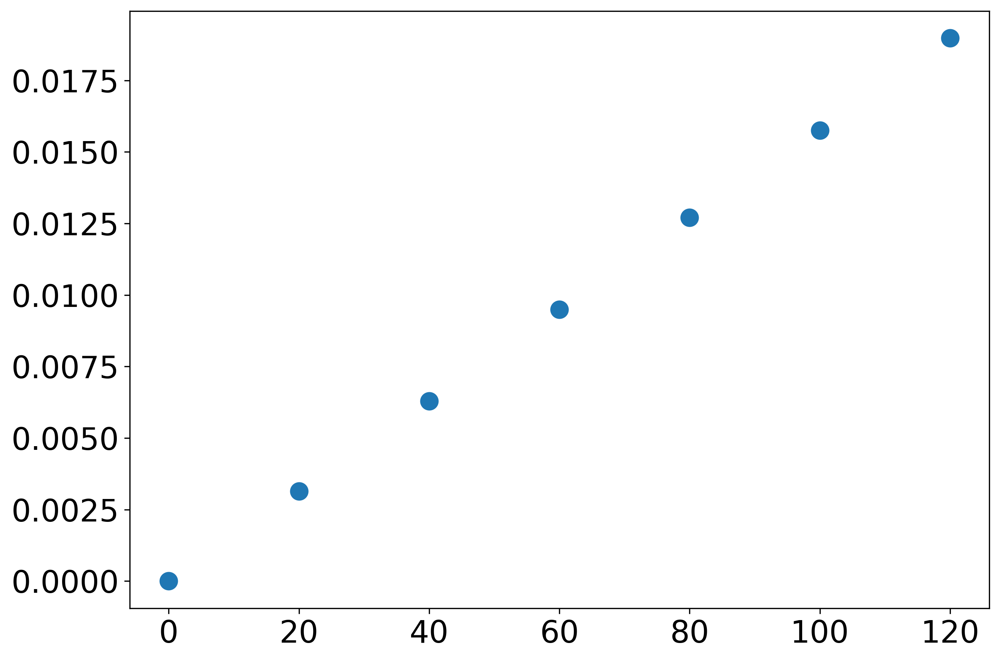

In [68]:

labels = ["C14", "C16", "C18"]
fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(
        time_initial_phase,  data_initial_phase[:, i], marker="o", linewidths=6, label =labels[i]
    )
    ax.plot(time_initial_phase, fatty_acids[:, i],  linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concemtration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    
    loc="best",
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()



In [ ]:
simulated_nefas = total_fatty_acid(
    system,
    par=par_fitting_two_emcee ,
    y0=y0,
    max_time= time_nefas1_simulation[-1],
    ncp_list= time_nefas1_simulation,
)


NameError: name 'par_fitting_two_emcee' is not defined

NameError: name 'simulated_nefas' is not defined

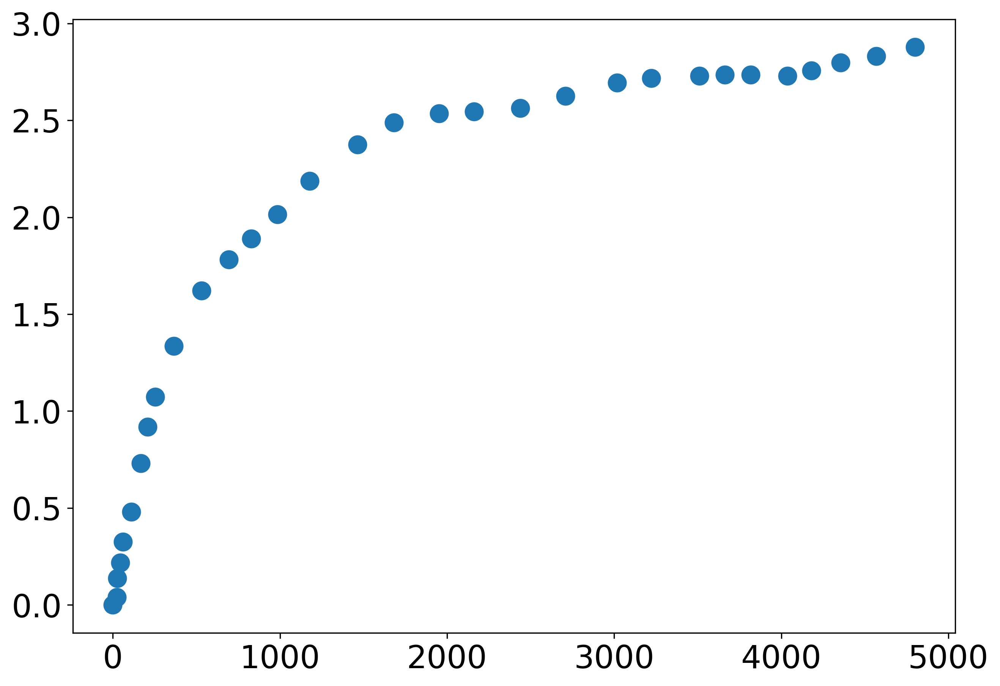

In [69]:
fig, ax = plt.subplots(figsize=(10, 7))


ax.scatter( time_nefas1_simulation, total_nefas1,  marker="o", linewidths=6)
ax.plot( time_nefas1_simulation, simulated_nefas,  linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concemtration ($\mu M $) ", fontsize=16)
plt.title("Concentrations over time ", fontsize=18)
# plt.yscale("log")
ax.legend(
    ["fit", "Total NEFAs data"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()


In [70]:
time_course1 = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA", "CoA"],
    ["E", "EC16", "ECoA", ],
    [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC18"],
    
    ["C14FA", "C16FA", "C18FA"],
]



### check the parameters on initial phase data 

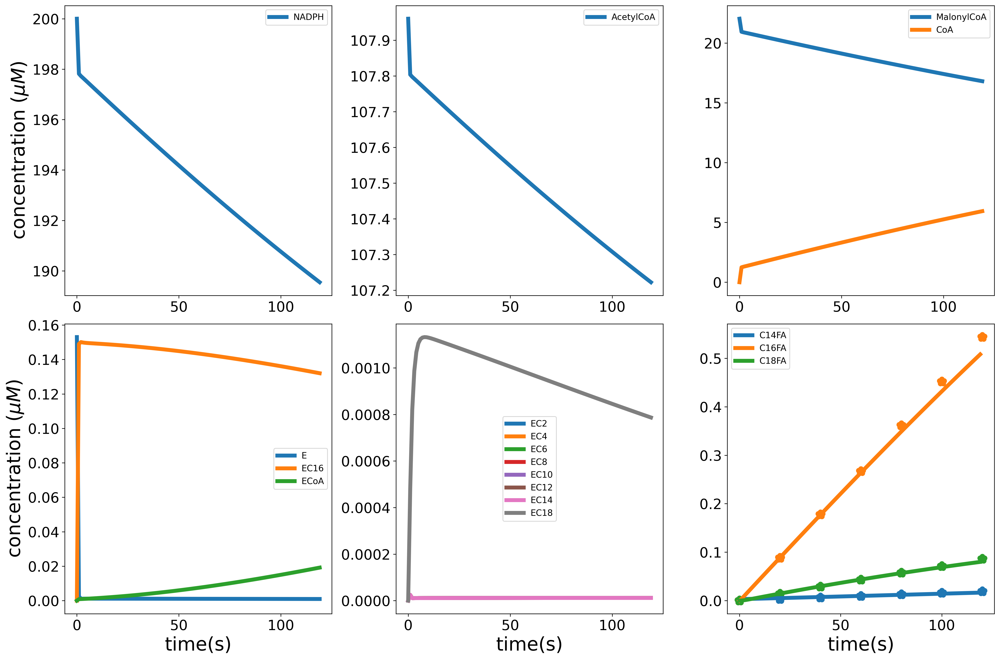

In [71]:
fig, axs = multi_plot_time_course(
    groups=time_course1,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par_fitting_two_lsq,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids = total_fatty_acid(
    system, par_fitting_two_lsq , y0, max_time= time_nefas1_simulation, ncp_list=ncp_list2
)

for i in range(3):
    axs[1, 2].scatter(time_initial_phase,  data_initial_phase[:, i], color = cols[i], marker="*", linewidth= 7)
plt.savefig(RESULTS_DIR /"initial_fitting_best.pdf",  dpi=300,  bbox_inches='tight')

In [72]:
par_fitting_two_lsq

{'beta': 0.04345734538274404,
 'kappa': 0.11647817468522687,
 'delta': 1.3021869110230178e-06,
 'kd6': 9.99999997374512,
 'kd7': 0.03,
 'kd8': 0.7000678571704833,
 'kf_CoA': 0.041485966570145194,
 'kb_CoA': 0.0002556790310327961,
 'y0_mal': 22.04}

### check the parameters on long run

In [73]:
time_course2 = [
 
    ["AcetylCoA", "NADPH"],
    ["MalonylCoA", "CoA"],
    ["E", "EC16", "ECoA", ],
    ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC18"],
    
    
]


In [75]:
fig, axs = multi_plot_time_course(
    groups=time_course2,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par_fitting_two_emcee,
    compounds=compounds,
    ncols=3,
    resizer=5,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids = total_fatty_acid(
    system, par_fitting_two_emcee, y0, max_time= time_nefas1_simulation, ncp_list=ncp_list2
)

axs[1, 1].scatter( time_nefas1_simulation, total_nefas1, marker ="o", linewidths=6, color=colors[i], label= "Total NEFAs" )
axs[1, 1].plot(ncp_list2, all_fatty_acids, linewidth=5)
axs[1, 1].legend([ "Simulations",  "Total NEFAs data"], fontsize =16)
axs[-1, -1].axis('off')
plt.savefig(RESULTS_DIR /"long_run_new_best.pdf",  dpi=300,  bbox_inches='tight')

NameError: name 'par_fitting_two_emcee' is not defined

In [76]:
ncp_list3 = [i for i in range(0, 50000)]
max_time3 =ncp_list3[-1]

fig, axs = multi_plot_time_course(
    groups=time_course1,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time3,
    ncp_list=ncp_list3,
    par=par_fitting_two_emcee,
    compounds=compounds,
    ncols=3,
    resizer=5,
    sharey=False,
    title=" Steady state behavior",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)


plt.savefig(RESULTS_DIR /"very_long_run_new_best.pdf",  dpi=300,  bbox_inches='tight')

NameError: name 'par_fitting_two_emcee' is not defined

In [77]:
long_run = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    # ["C14FA"],
    # ["C16FA"],
    # ["C18FA"],
    # ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    # [
    #     "C14FA",
    #     "C16FA",
    #     "C18FA",
    # ],
]

fig, axs = multi_plot_time_course(
    groups=long_run,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par_fitting_two_emcee ,
    compounds=compounds,
    ncols=2,
    resizer=8,
    sharey=False,
    title="Long run and fitting total NEFAs",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
#adding data to a particular graph
all_fatty_acids= total_fatty_acid(system, par_fitting_two_emcee , y0, max_time =  time_nefas1_simulation, ncp_list = ncp_list2)

axs[1, 1].scatter( time_nefas1_simulation, total_nefas1,  marker = "s", linewidths=7, color=cols[1])
axs[1, 1].plot(ncp_list2, all_fatty_acids, color= cols[2], linewidth=5)
axs[1, 1].legend(
    [

    "simulated total NEFAs ",
    "Data total NEFAs",
    ],
prop={'size': 20}
)
plt.tick_params(axis="both", labelsize=18)
plt.savefig(RESULTS_DIR /"long_run_new.pdf",  dpi=300,  bbox_inches='tight')


NameError: name 'par_fitting_two_emcee' is not defined

In [78]:
# !!! emcee does not -- and cannot -- actually do a fit. It can explore parameter space, which can for sure be useful, but it never has any intention of finding an improved solution.

In [79]:
initial_comp = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    # ["C14FA"],
    # ["C16FA"],
    # ["C18FA"],
    # ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    [
        "C14FA",
         "C16FA",
     "C18FA",
    ],
]

fig, axs = multi_plot_time_course(
    groups=initial_comp,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par_fitting_two_emcee ,
    compounds=compounds,
    ncols=2,
    resizer=8,
    sharey=False,
    title="Initial phase and fitting Topolska data",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
#adding data to a particular graph
fatty_acids= fatty_acid_of_interest(system, par_fitting_two_emcee , y0, max_time = time_initial_phase[-1], ncp_list = time_initial_phase)
for i in range(3):
    axs[1, 1].scatter(time_initial_phase,  data_initial_phase[:,i],  marker = "s", linewidths=8, color=cols[i])
#axs[1, 1].plot(time_initial_phase, fatty_acids, linewidth=5)
# axs[1, 1].legend(
#     [

#     "simulated",
#     "Data total NEFAs",
#     ],
# prop={'size': 20}
# )
plt.tick_params(axis="both", labelsize=20)

plt.savefig(RESULTS_DIR /"initial_new.pdf",  dpi=300,  bbox_inches='tight')


NameError: name 'par_fitting_two_emcee' is not defined

In [80]:
goodness_of_fit( data_initial_phase, fatty_acids)

NameError: name 'fatty_acids' is not defined

In [81]:
list_sample= [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA","CoA"],
    
    ["E","EC16", "ECoA"],
     ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14",  "EC18"],
     
     ["C14FA", "C16FA", "C18FA",]
    
]


colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=list_sample,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par_fitting_two_emcee,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title="Version1: Conserved enzyme",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
plt.tick_params(axis="both", labelsize=14)
# adding data to a particular graph
# for i in range(3):
#        axs[1, 1].plot(time_initial_phase,  initial_phase_data[:, i], "o", color=colors[i])

# plt.tick_params(axis="both", labelsize=14)
plt.savefig(RESULTS_DIR /"init12.pdf", dpi=300)


NameError: name 'par_fitting_two_emcee' is not defined

In [82]:
base_line_parameters = par_fitting_two_lsq.copy()
param = pd.DataFrame(
    {"Name ":par_fitting_two_lsq.keys(), " value": par_fitting_two_lsq.values()}
)
param

,Name,value
0,beta,0.043457
1,kappa,0.116478
2,delta,0.000001
3,kd6,10.000000
4,kd7,0.030000
5,kd8,0.700068
6,kf_CoA,0.041486
7,kb_CoA,0.000256
8,y0_mal,22.040000


In [83]:
fat_track =[
    ["C14FA"],
    ["C16FA"],
    ["C18FA"],
  
]



fat_track =[
    ["C14FA"],
    ["C16FA"],
    ["C18FA"],
  
]

def fititing_var(par,par_interest, n_instance, var_percent, transp =0.02): 
    par1 =  par.copy()

    best_par =  par1[par_interest]
    lower_bound = best_par - best_par*var_percent

    upper_bound = best_par + best_par*var_percent
    if lower_bound<0:
        lower_bound = 0
    par_range = np.linspace(lower_bound, upper_bound, n_instance)
    best_line = total_fatty_acid(system,  par1  , y0, max_time = time_nefas1_simulation, ncp_list = time_nefas1_simulation)
    



    fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(8, 8))

    for j in par_range:
        par1[par_interest] = j
        y = total_fatty_acid(system, par1  , y0, max_time = time_nefas1_simulation, ncp_list = time_nefas1_simulation)
        axs.plot(time_nefas1_simulation, y,  linewidth = 6,  alpha=transp, label = f"{par_interest} = {round(j, 3)}")
        
    axs.plot(time_nefas1_simulation, best_line,  linewidth = 6, label = f"baseline ({par_interest}= {round(par[par_interest], 3)})", color ="b")
    axs.scatter(time_nefas1_simulation, total_nefas1, marker="*", color = "k", linewidth = 6, label = "data")
    axs.legend(loc="best", fontsize= 20)

    fig.suptitle(f'Impact  of the {par_interest} on the dynamics', fontsize=28.0, fontname="serif", fontweight="bold", y =1.01)

    axs.tick_params(axis="both", labelsize=20)
    fig.patch.set_alpha(0.0)
        
        
    fig.tight_layout()
        
        

In [84]:
base_line_parameters =par_fitting_two_lsq.copy()
param = pd.DataFrame(
    {"Name ":par_fitting_two_lsq.keys(), " value": par_fitting_two_lsq.values()}
)
param

,Name,value
0,beta,0.043457
1,kappa,0.116478
2,delta,0.000001
3,kd6,10.000000
4,kd7,0.030000
5,kd8,0.700068
6,kf_CoA,0.041486
7,kb_CoA,0.000256
8,y0_mal,22.040000


findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times


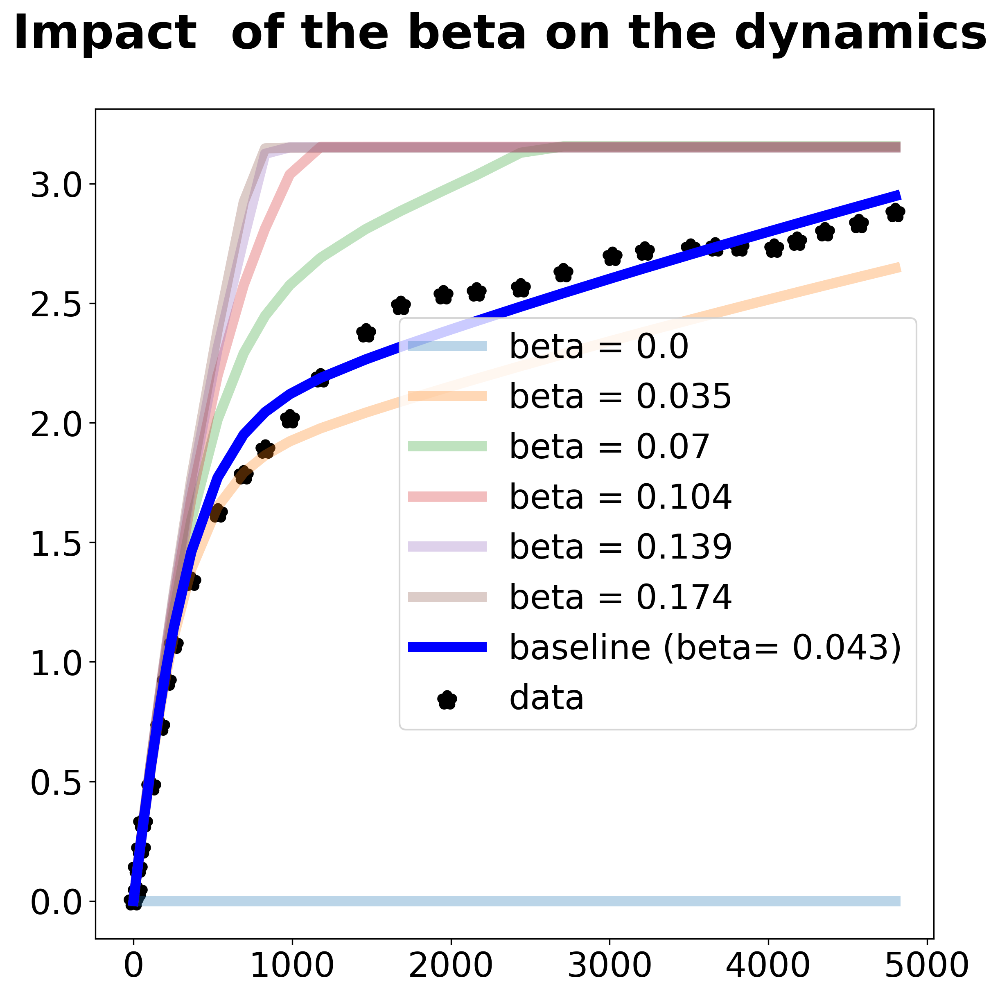

In [85]:
fititing_var(par = base_line_parameters,par_interest = "beta", n_instance=6, var_percent=3,transp=0.3)
plt.savefig(RESULTS_DIR /"beta_var", dpi =300,  bbox_inches='tight')

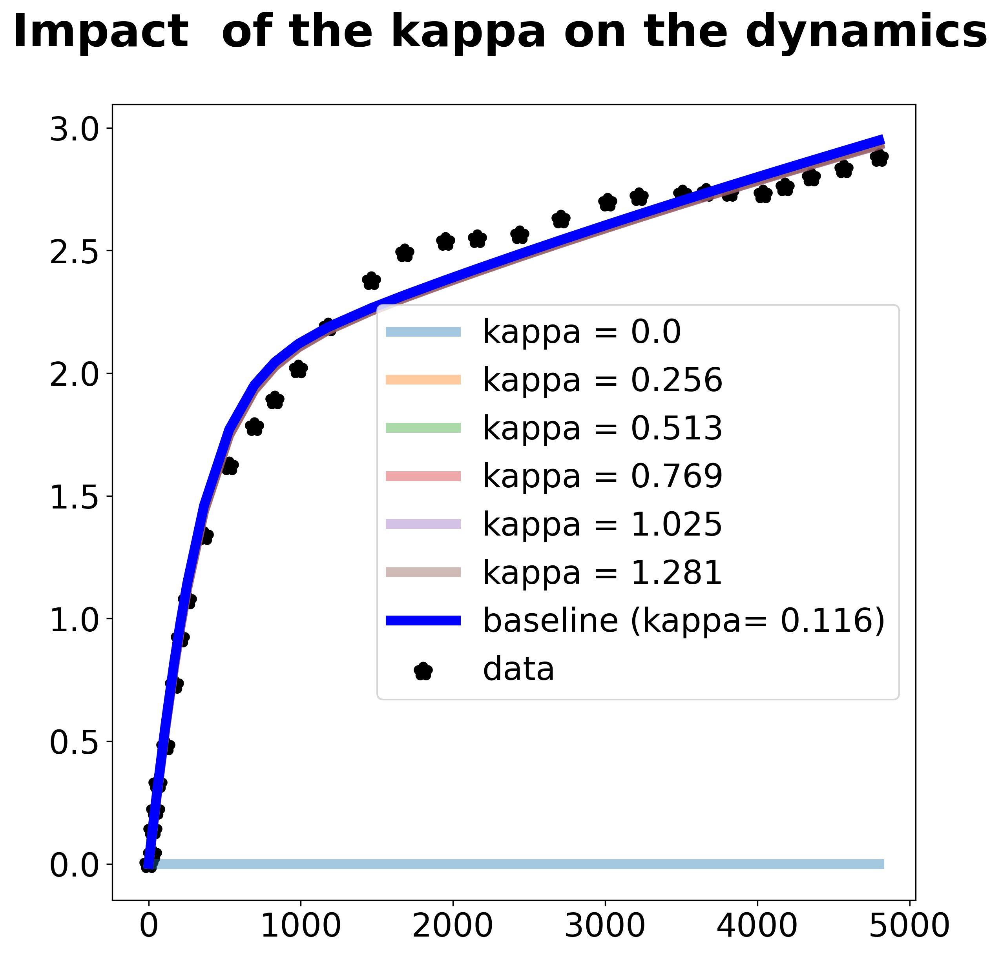

In [86]:
fititing_var(par = base_line_parameters,par_interest = "kappa", n_instance=6, var_percent=10,transp=0.4)
plt.savefig(RESULTS_DIR /"kappa_var", dpi =300,  bbox_inches='tight')

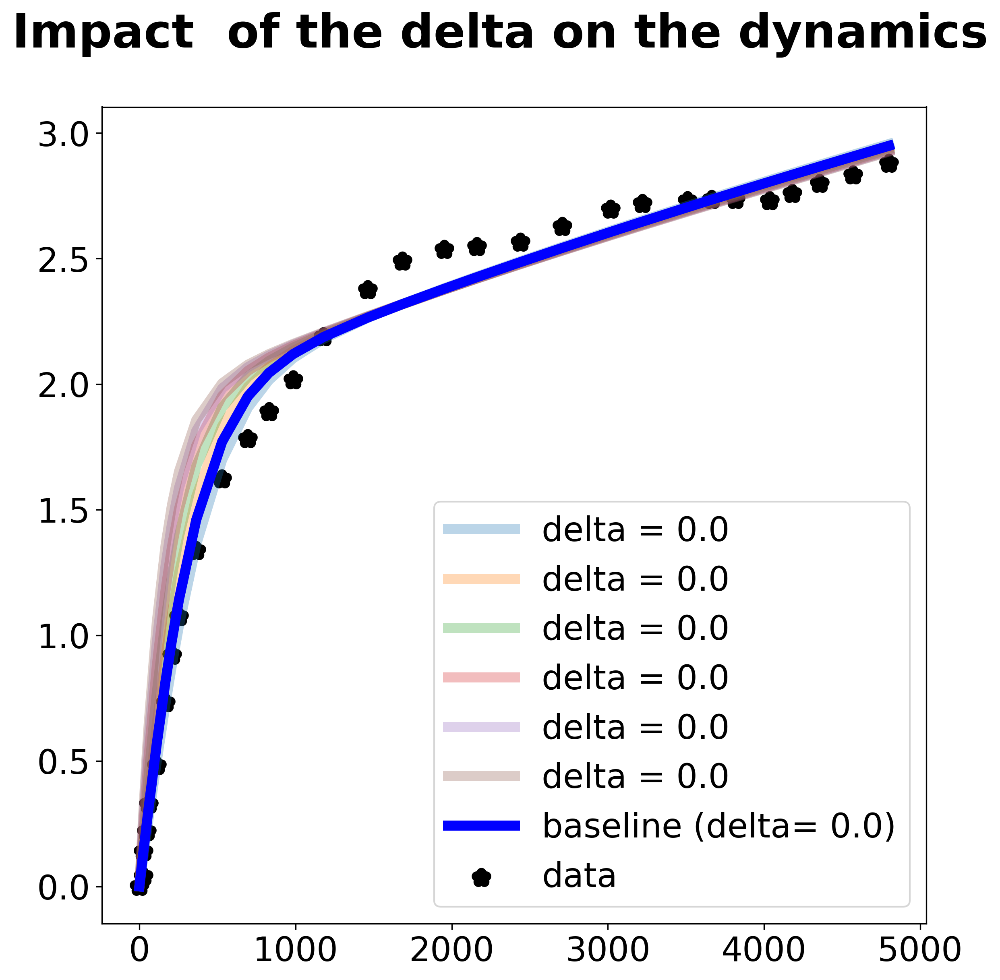

In [87]:
fititing_var(par = base_line_parameters,par_interest = "delta", n_instance=6, var_percent=10,transp=0.3)
plt.savefig(RESULTS_DIR /"delta_var", dpi =300,  bbox_inches='tight')

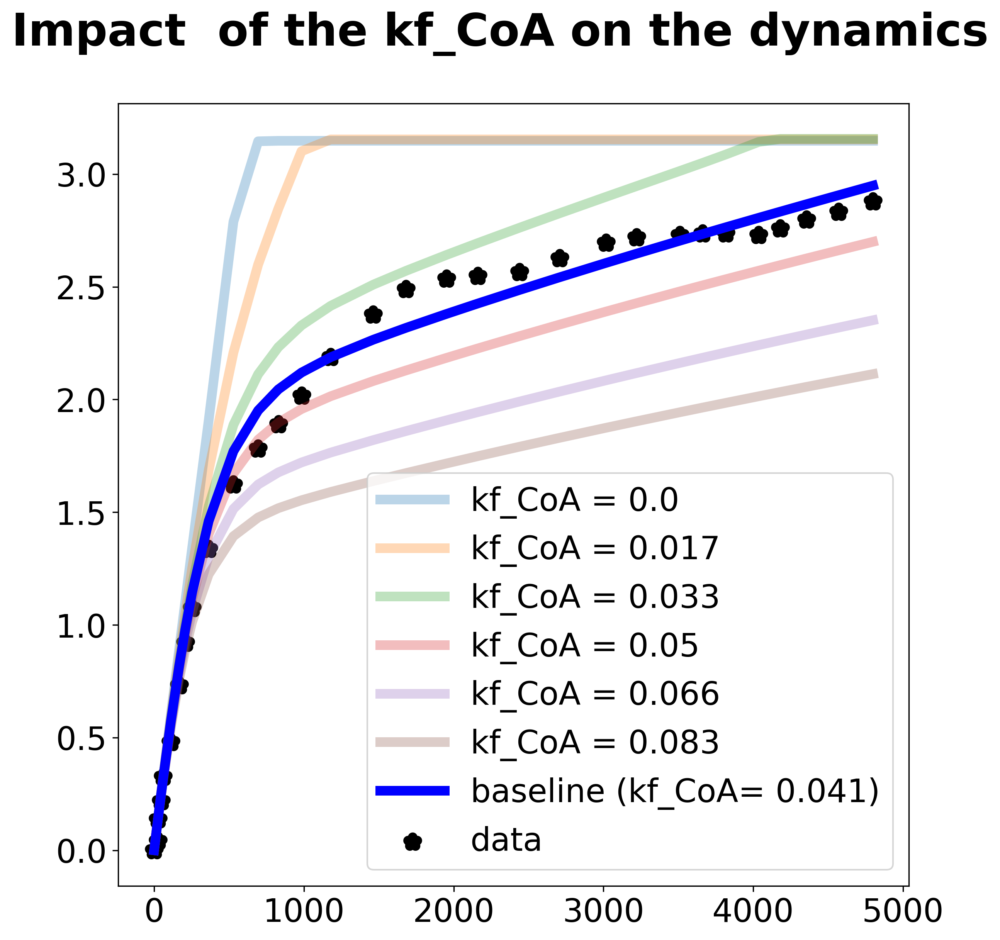

In [88]:
fititing_var(par = base_line_parameters,par_interest = "kf_CoA", n_instance=6, var_percent=1,transp=0.3)
plt.savefig(RESULTS_DIR /"kfcoA_var", dpi =300,  bbox_inches='tight')

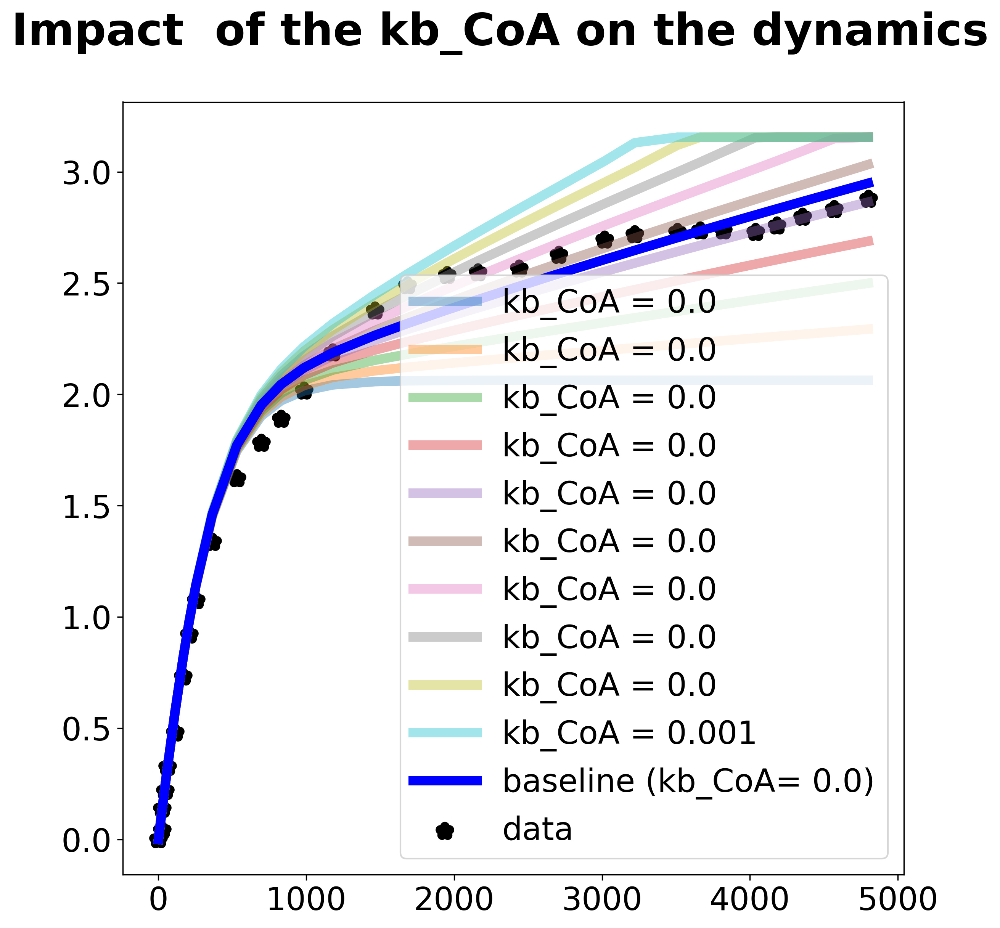

In [89]:
fititing_var(par = base_line_parameters,par_interest = "kb_CoA", n_instance=10, var_percent=1,transp=0.4)
plt.savefig(RESULTS_DIR /"kb_CoA_var", dpi =300,  bbox_inches='tight')

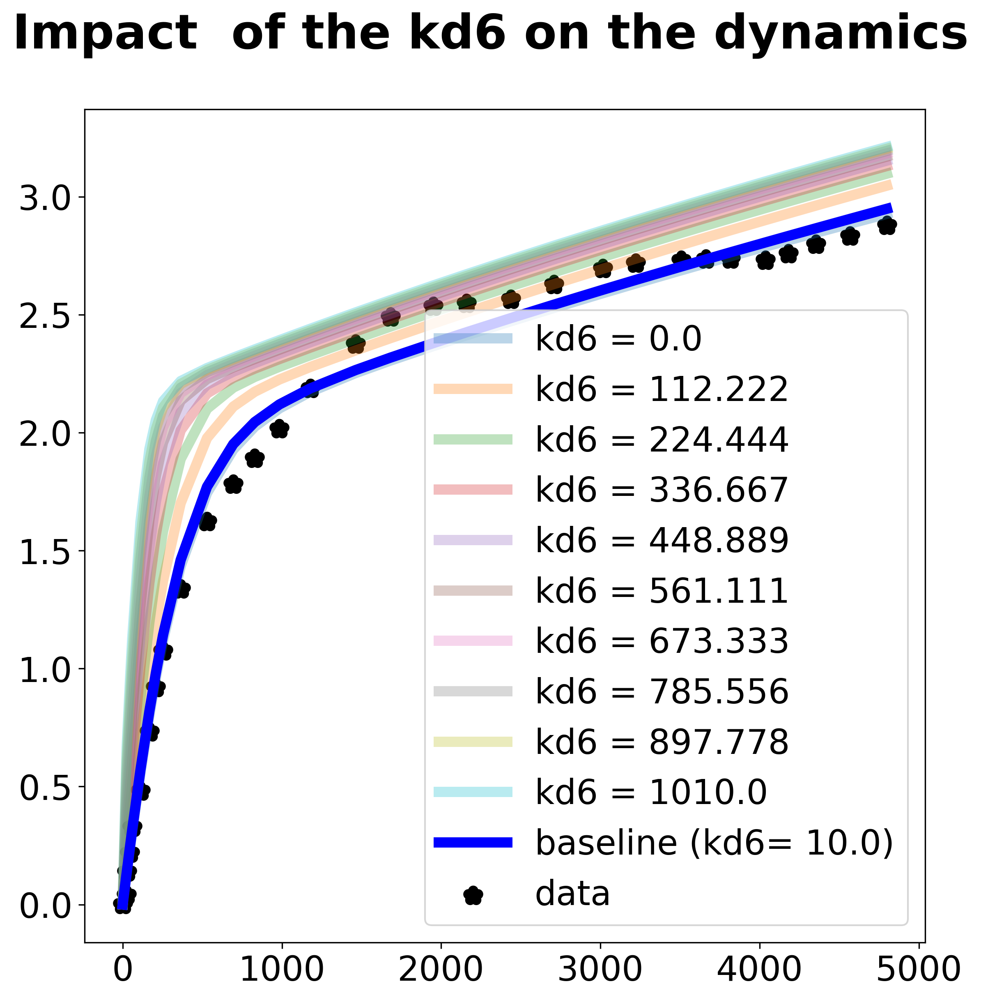

In [90]:
fititing_var(par = base_line_parameters,par_interest = "kd6", n_instance=10, var_percent=100,transp=0.3)
plt.savefig(RESULTS_DIR /"kd7_var", dpi =300,  bbox_inches='tight')

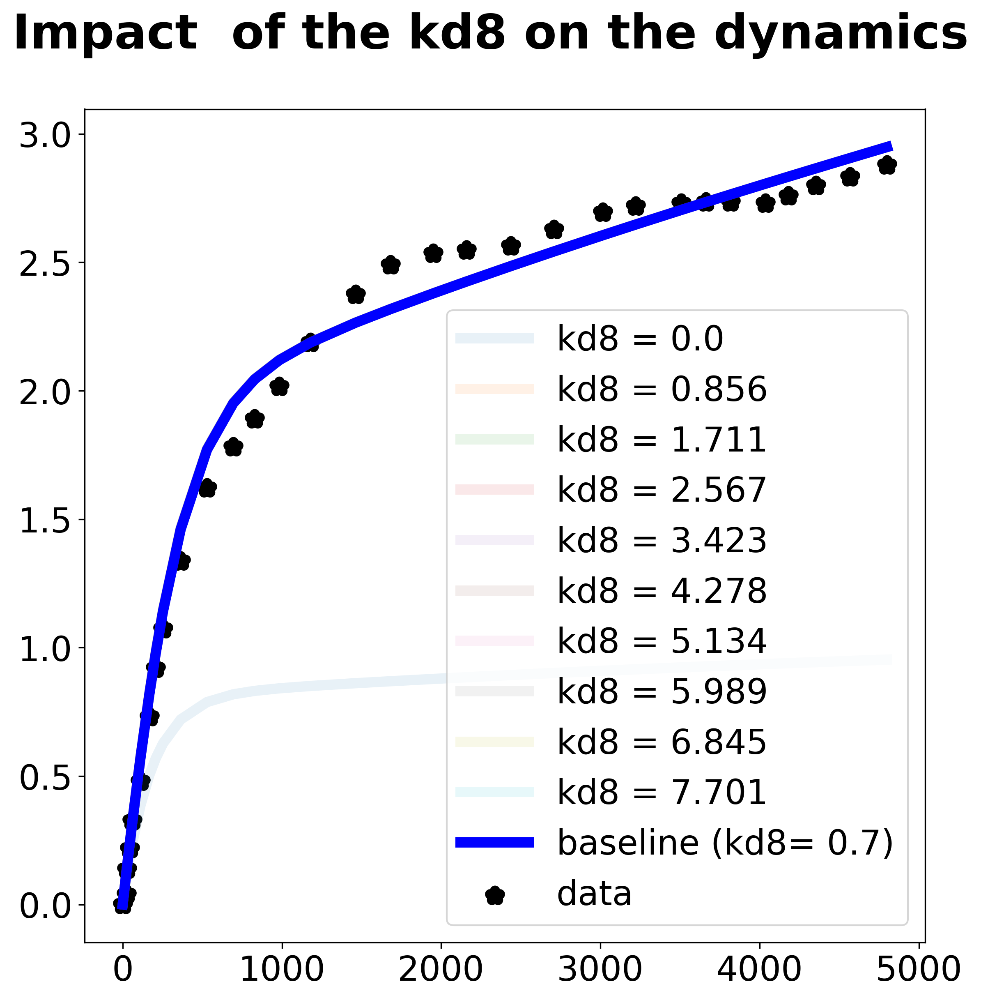

In [91]:
fititing_var(par = base_line_parameters,par_interest = "kd8", n_instance=10, var_percent=10,transp=0.1)
plt.savefig(RESULTS_DIR /"kd8_var", dpi =300,  bbox_inches='tight')

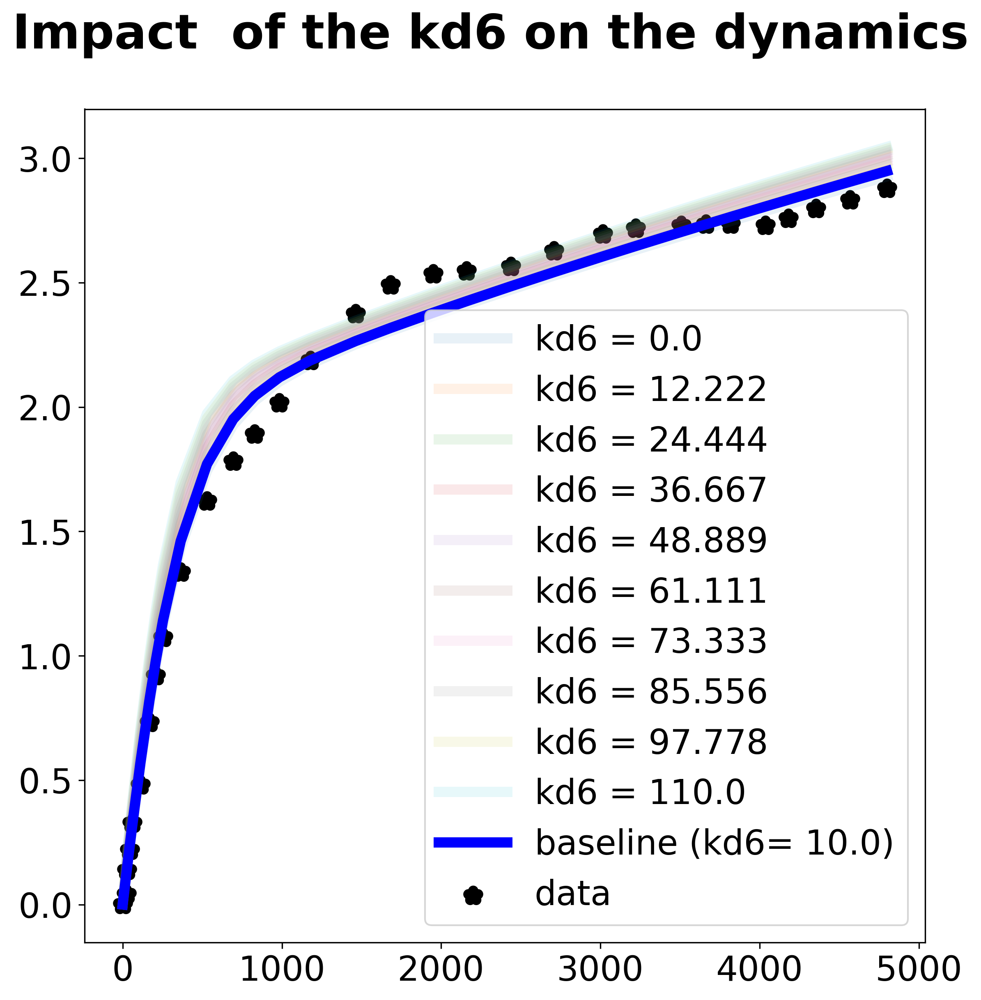

In [92]:
fititing_var(par = base_line_parameters,par_interest = "kd6", n_instance=10, var_percent=10,transp=0.1)
plt.savefig(RESULTS_DIR /"kd6_var", dpi =300,  bbox_inches='tight')

In [93]:
# perc= 1
# fact_upper_bound =50
# problem = {
#     "num_vars":8,
#     "names": [
#         "beta",
#         "kappa",
#         "delta",
#         # "kd1",
#         # "kd2",
#         # "kd3",
#         # "kd4",
#         # "kd5",
#         "kd6",
#         "kd7",
#         "kd8",
#         "kf_CoA",
#         "kb_CoA",
#     ],
#     "bounds": [
#         [base_line_parameters["beta"] - perc*base_line_parameters["beta"], base_line_parameters["beta"] + fact_upper_bound*perc*base_line_parameters["beta"]],
#         [base_line_parameters["kappa"] - perc*base_line_parameters["kappa"], base_line_parameters["kappa"] + fact_upper_bound*perc*base_line_parameters["kappa"]],
#         [base_line_parameters["delta"] - perc*base_line_parameters["delta"], base_line_parameters["delta"] + fact_upper_bound*perc*base_line_parameters["delta"]],
#         # [base_line_parameters["kd1"] - perc*base_line_parameters["kd1"], base_line_parameters["kd1"] + perc*base_line_parameters["kd1"]+1e-25],
#         # [base_line_parameters["kd2"] - perc*base_line_parameters["kd2"], base_line_parameters["kd2"] + perc*base_line_parameters["kd2"]+1e-25],
#         # [base_line_parameters["kd3"] - perc*base_line_parameters["kd3"], base_line_parameters["kd3"] + perc*base_line_parameters["kd3"]+1e-25],
#         # [base_line_parameters["kd4"] - perc*base_line_parameters["kd4"], base_line_parameters["kd4"] + perc*base_line_parameters["kd4"]+1e-25],
#         # [base_line_parameters["kd5"] - perc*base_line_parameters["kd5"], base_line_parameters["kd5"] + perc*base_line_parameters["kd5"]+1e-25],
#         [base_line_parameters["kd6"] - perc*base_line_parameters["kd6"], base_line_parameters["kd6"] + fact_upper_bound*perc*base_line_parameters["kd6"]],
#         [base_line_parameters["kd7"] - perc*base_line_parameters["kd7"], base_line_parameters["kd7"] + fact_upper_bound*perc*base_line_parameters["kd7"]],
#         [base_line_parameters["kd8"] - perc*base_line_parameters["kd8"], base_line_parameters["kd8"] + fact_upper_bound*perc*base_line_parameters["kd8"]],
#         [base_line_parameters["kf_CoA"] - perc*base_line_parameters["kf_CoA"], base_line_parameters["kf_CoA"] + fact_upper_bound*perc*base_line_parameters["kf_CoA"]],
#         [base_line_parameters["kb_CoA"] - perc*base_line_parameters["kb_CoA"], base_line_parameters["kb_CoA"] + fact_upper_bound*perc*base_line_parameters["kb_CoA"]],
#     ],
    
# }
# print(problem["bounds"])



# param_values = saltelli.sample(problem, 2048, calc_second_order=True, skip_values=2048)

# def func(values: list[float], names: list[str]):
    
#     param_dict=dict(zip(names, values))
#     return    (
#             fatty_acid_of_interest(
#                 system,
#                param_dict,
#                 y0,
#                 max_time= time_nefas1_simulation,
#                 ncp_list= time_nefas1_simulation,
#             )[-1]
#         )

# with ProcessPoolExecutor() as executor:
#     names = problem["names"]
#     y = list(executor.map(func, param_values, it.repeat(names)))
    
# Y = np.array(y)



In [96]:
time_sens = np.linspace(0,450,2000)
max_time_sens = time_sens[-1]
y0

array([1.0796e+02, 2.2040e+01, 0.0000e+00, 0.0000e+00, 0.0000e+00,
       0.0000e+00, 1.5300e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00,
       0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
       0.0000e+00, 0.0000e+00, 2.0000e+02])

In [97]:
plt.rcParams.update({"figure.dpi": "300"})
plt.rcParams.update(
    {
        "font.family": "serif",  # specify font family here
        "font.serif": ["Times"],  # specify font here
        "font.size": 11,
    }
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cols = [f"{color}" for color in colors]

In [98]:
perc= 1
sample_size =2**11
fact_upper_bound =50
problem = {
    "num_vars":8,
    "names": [
        "beta",
        "kappa",
        "delta",
        # "kd1",
        # "kd2",
        # "kd3",
        # "kd4",
        # "kd5",
        "kd6",
        "kd7",
        "kd8",
        "kf_CoA",
        "kb_CoA",
    ],
    "bounds": [
        [0,1e1],
        [0,1e1],
        [0,1e1],
        [0,1e1],
        [0,1e1],
        [0,1e1],
        [0,1e1],
        [0,1e1],
    ],
    
}
print(problem["bounds"])



param_values = saltelli.sample(problem,
                              sample_size, 
                               calc_second_order=True, 
                               #skip_values=4096
                               )

def func(values: list[float], names: list[str]):
    
    param_dict=dict(zip(names, values))
    expr = (
            fatty_acid_of_interest(
                system,
               param_dict,
                y0,
                max_time= max_time_sens,
                ncp_list= time_sens,
            )
        )
    # normalize the data
    norm1 = expr  / np.linalg.norm(expr )
    return norm1.mean(axis=0)

with ProcessPoolExecutor() as executor:
    names = problem["names"]
    y = list(executor.map(func, param_values, it.repeat(names)))
    
Y = np.array(y)



[[0, 10.0], [0, 10.0], [0, 10.0], [0, 10.0], [0, 10.0], [0, 10.0], [0, 10.0], [0, 10.0]]


In [99]:
label_S1_ST=(r'$\beta$',
 r'$\kappa$',
 r'$\delta$',
 r'$k_{d6}$',
 r'$k_{d7}$',
 r'$k_{d8}$',
 r'$k_{fCoA}$',
 r'$k_{bCoA}$')

label_S1_ST

('$\\beta$',
 '$\\kappa$',
 '$\\delta$',
 '$k_{d6}$',
 '$k_{d7}$',
 '$k_{d8}$',
 '$k_{fCoA}$',
 '$k_{bCoA}$')

In [100]:
label_S2 = (
r"($\beta$, $\kappa$)",
 r"($\beta$, $\delta$)",
 r"($\beta$, $k_{d6}$)",
 r"($\beta$, $k_{d7}$)",
 r"($\beta$, $k_{d8}$)",
 r"($\beta$, $k_{fCoA}$)",
 r"($\beta$, $k_{bCoA}$)",
 r"($\kappa$, $\delta$)",
 r"($\kappa$, $k_{d6}$)",
 r"($\kappa$, $k_{d7}$)",
 r"($\kappa$, $k_{d8}$)",
 r"($\kappa$, $k_{fCoA}$)",
 r"($\kappa$, $k_{bCoA}$)",
 r"($\delta$, $k_{d6}$)",
  r"($\delta$, $k_{d7}$)",
  r"($\delta$, $k_{d8}$)",
  r"($\delta$, $k_{fCoA}$)",
  r"($\delta$, $k_{bCoA}$)",
 r"($k_{d6}$, $k_{d7}$)",
 r"($k_{d6}$, $k_{d8}$)",
 r"($k_{d6}$, $k_{fCoA}$)",
 r"($k_{d6}$, $k_{bCoA}$)",
 r"($k_{d7}$, $k_{d8}$)",
r"($k_{d7}$, $k_{fCoA}$)",
r"($k_{d7}$, $k_{bCoA}$)",
r"($k_{d8}$, $k_{fCoA}$)",
r"($k_{d8}$, $k_{bCoA}$)",
r"($k_{fCoA}$, $k_{fCoA}$)"

)

In [101]:
Si_C14 = sobol.analyze(problem, Y[:, 0], print_to_console=False)
Si_C16 = sobol.analyze(problem, Y[:, 1], print_to_console=False)
Si_C18 = sobol.analyze(problem, Y[:, 2], print_to_console=False)



In [102]:
Saltelli_TC14, Saltelli_1stC14, Saltelli_2stC14 = Si_C14.to_df()
Saltelli_TC16, Saltelli_1stC16, Saltelli_2stC16 = Si_C16.to_df()
Saltelli_TC18, Saltelli_1stC18, Saltelli_2stC18 = Si_C18.to_df()


In [103]:
dfS1 = pd.concat(
    {"C14":Saltelli_1stC14,
"C16":Saltelli_1stC16,
"C18":Saltelli_1stC18,
     }
)
dfS2 =pd.concat(
    {"C14":Saltelli_2stC14,
"C16":Saltelli_2stC16,
"C18":Saltelli_2stC18,
     }
)
dfST = pd.concat(
    {"C14":Saltelli_TC14,
"C16":Saltelli_TC16,
"C18":Saltelli_TC18,
     }
)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


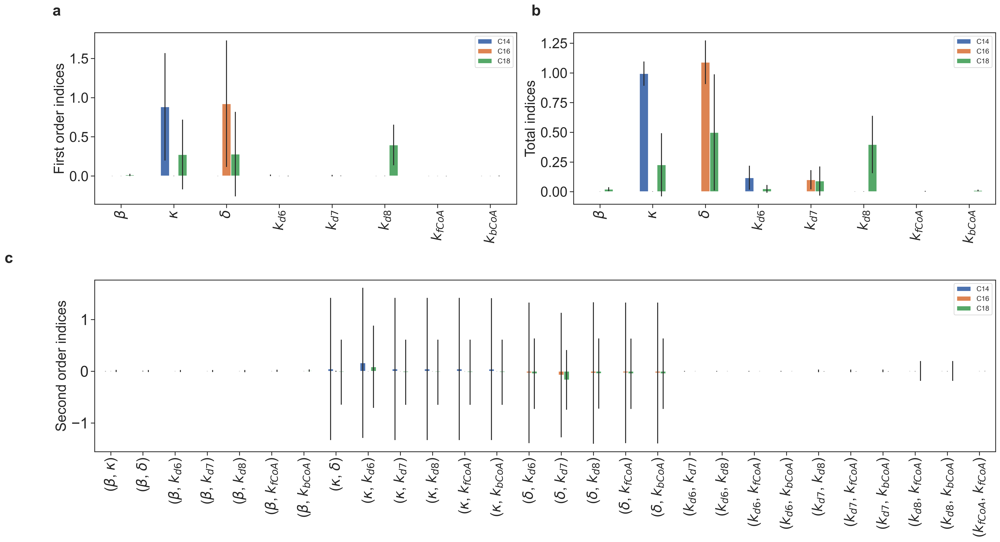

In [104]:
sns.set() 
sns.set_style("ticks")

fig = plt.figure(tight_layout=True, figsize=(22, 12))
gs = gridspec.GridSpec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

dfS1["S1"].unstack().T.plot(kind="bar", yerr=dfS1["S1_conf"].unstack().T, ax=ax1,width =0.5 )
dfST["ST"].unstack().T.plot(kind="bar", yerr=dfST["ST_conf"].unstack().T, ax=ax2,width =0.5 )
dfS2["S2"].unstack().T.plot(kind="bar", yerr=dfS2["S2_conf"].unstack().T, ax=ax3,width =0.5  )

ax1.set_ylabel("First order indices", fontsize=22)
ax2.set_ylabel("Total indices", fontsize=22)
ax3.set_ylabel("Second order indices", fontsize=22)


ax1.tick_params(axis="x", labelsize=22)
ax2.tick_params(axis="x", labelsize=22)
ax3.tick_params(axis="x", labelsize=22)

ax1.tick_params(axis="y", labelsize=22)
ax2.tick_params(axis="y", labelsize=22)
ax3.tick_params(axis="y", labelsize=24)

ax1.text(-0.1, 1.1, string.ascii_lowercase[0], transform=ax1.transAxes, 
            size=24, weight='bold')
ax2.text(-0.1, 1.1, string.ascii_lowercase[1], transform=ax2.transAxes, 
            size=24, weight='bold')
ax3.text(-0.1, 1.1, string.ascii_lowercase[2], transform=ax3.transAxes, 
            size=24, weight='bold')
ax1.set_xticklabels( label_S1_ST,fontsize=22)
ax2.set_xticklabels( label_S1_ST,fontsize=22)
ax3.set_xticklabels( label_S2,fontsize=22)


fig.patch.set_alpha(0.0)

plt.tight_layout()
fig.savefig(RESULTS_DIR /"sobol_examp1.eps", dpi =300,  bbox_inches='tight')

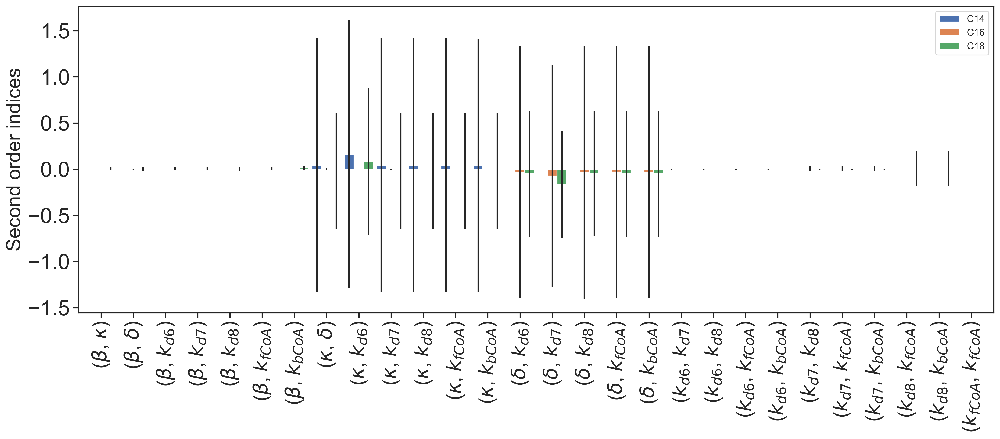

In [105]:
sns.set() 
sns.set_style("ticks")

fig = plt.figure(tight_layout=True, figsize=(30, 12))
gs = gridspec.GridSpec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])

dfS2["S2"].unstack().T.plot(kind="bar", yerr=dfS2["S2_conf"].unstack().T, ax=ax1, width =0.9, align='center')

ax1.set_ylabel("Second order indices", fontsize=22)
ax1.tick_params(axis="x", labelsize=22)
ax1.tick_params(axis="y", labelsize=24)

ax1.set_xticklabels( label_S2,fontsize=22)

fig.patch.set_alpha(0.01)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


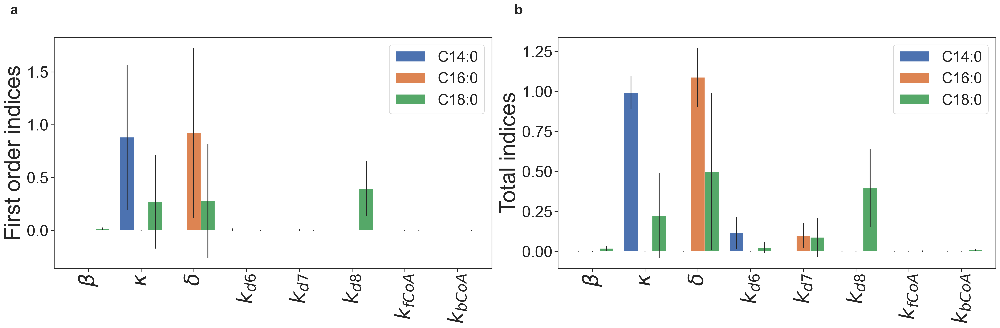

In [106]:
sns.set()
sns.set_style("ticks")

fig = plt.figure(tight_layout=True, figsize=(24, 8))
gs = gridspec.GridSpec(1, 2)


ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
#ax3 = fig.add_subplot(gs[1, :])

dfS1["S1"].unstack().T.plot(
    kind="bar", yerr=dfS1["S1_conf"].unstack().T, ax=ax1, width=0.8, 
)
dfST["ST"].unstack().T.plot(
    kind="bar", yerr=dfST["ST_conf"].unstack().T, ax=ax2, width=0.8
)
dfS2["S2"].unstack().T.plot(
    kind="bar", yerr=dfS2["S2_conf"].unstack().T, ax=ax3, width=0.8
)

ax1.set_ylabel("First order indices", fontsize=38)
ax2.set_ylabel("Total indices", fontsize=38)
#ax3.set_ylabel("Second order indices", fontsize=16)


ax1.tick_params(axis="x", labelsize=22)
ax2.tick_params(axis="x", labelsize=22)
#ax3.tick_params(axis="x", labelsize=22)

ax1.tick_params(axis="y", labelsize=27)
ax2.tick_params(axis="y", labelsize=27)
#ax3.tick_params(axis="y", labelsize=24)

ax1.text(
    -0.1,
    1.1,
    string.ascii_lowercase[0],
    transform=ax1.transAxes,
    size=24,
    weight="bold",
)
ax2.text(
    -0.1,
    1.1,
    string.ascii_lowercase[1],
    transform=ax2.transAxes,
    size=24,
    weight="bold",
)
# ax3.text(
#     -0.1,
#     1.1,
#     string.ascii_lowercase[2],
#     transform=ax3.transAxes,
#     size=24,
#     weight="bold",
# )
ax1.set_xticklabels(label_S1_ST, fontsize=36)
ax2.set_xticklabels(label_S1_ST, fontsize=36)
#ax3.set_xticklabels(label_S2, fontsize=22)

ax1.legend(["C14:0", "C16:0", "C18:0"],loc='best', prop={'size': 26})
ax2.legend(["C14:0", "C16:0", "C18:0"],loc='best', prop={'size': 26})

fig.patch.set_alpha(0.0)



plt.tight_layout()
fig.savefig(RESULTS_DIR / "sensitivity_analysis_CoA_model.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


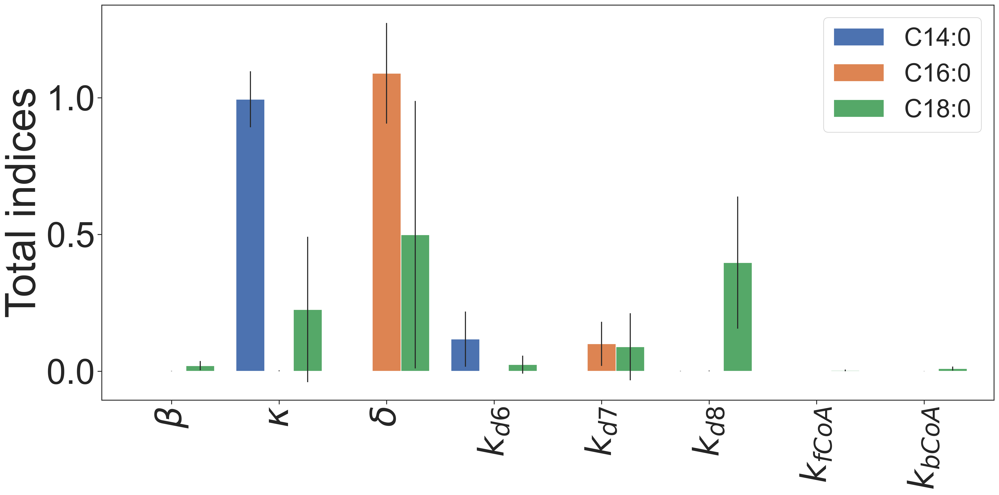

In [107]:
sns.set()
sns.set_style("ticks")

fig = plt.figure(tight_layout=True, figsize=(20, 10))
gs = gridspec.GridSpec(1, 1)


ax1 = fig.add_subplot(gs[0, 0])
#ax2 = fig.add_subplot(gs[0, 1])
#ax3 = fig.add_subplot(gs[1, :])

# dfS1["S1"].unstack().T.plot(
#     kind="bar", yerr=dfS1["S1_conf"].unstack().T, ax=ax1, width=0.8, 
# )
dfST["ST"].unstack().T.plot(
    kind="bar", yerr=dfST["ST_conf"].unstack().T, ax=ax1, width=0.8
)
dfS2["S2"].unstack().T.plot(
    kind="bar", yerr=dfS2["S2_conf"].unstack().T, ax=ax3, width=0.8
)

ax1.set_ylabel("Total indices", fontsize=60)
# ax2.set_ylabel("Total indices", fontsize=38)
#ax3.set_ylabel("Second order indices", fontsize=16)


ax1.tick_params(axis="x", labelsize=32)
# ax2.tick_params(axis="x", labelsize=22)
#ax3.tick_params(axis="x", labelsize=22)

ax1.tick_params(axis="y", labelsize=50)
# ax2.tick_params(axis="y", labelsize=27)
#ax3.tick_params(axis="y", labelsize=24)

# ax1.text(
#     -0.1,
#     1.1,
#     string.ascii_lowercase[0],
#     transform=ax1.transAxes,
#     size=20,
#     weight="bold",
# )
# ax2.text(
#     -0.1,
#     1.1,
#     string.ascii_lowercase[1],
#     transform=ax2.transAxes,
#     size=20,
#     weight="bold",
# )
# ax3.text(
#     -0.1,
#     1.1,
#     string.ascii_lowercase[2],
#     transform=ax3.transAxes,
#     size=24,
#     weight="bold",
# )
ax1.set_xticklabels(label_S1_ST, fontsize=50)
# ax2.set_xticklabels(label_S1_ST, fontsize =36)
#ax3.set_xticklabels(label_S2, fontsize=22)

ax1.legend(["C14:0", "C16:0", "C18:0"],loc='best',
           prop={'size': 36}
           )
# ax2.legend(["C14:0", "C16:0", "C18:0"],loc='best', 
#            prop={'size': 26}
#            )

fig.patch.set_alpha(0.0)



plt.tight_layout()
fig.savefig(RESULTS_DIR / "sensitivity_analysis_CoA_modelST.eps", dpi=300, bbox_inches="tight")

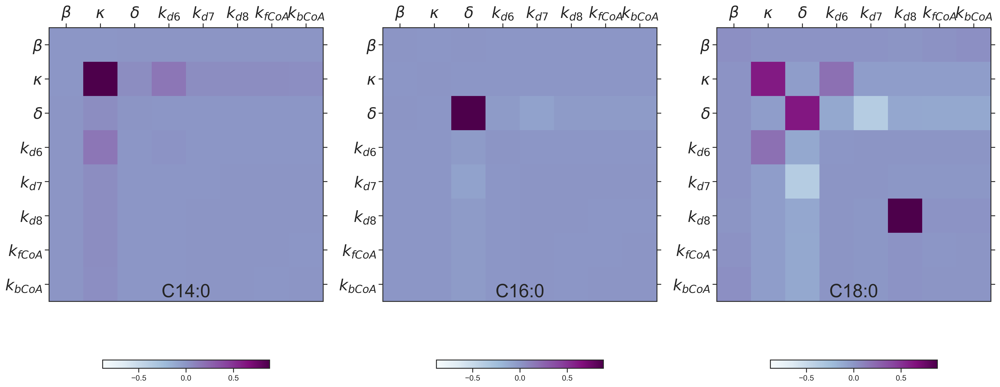

In [108]:
import matplotlib.ticker as mticker
n_params = problem["num_vars"]
comp_matrix_C14 = np.ndarray(shape = (n_params,n_params))
comp_matrix_C16 = np.ndarray(shape = (n_params,n_params))
comp_matrix_C18 = np.ndarray(shape = (n_params,n_params))
for j in range(n_params):
    for i in range(n_params):
        if i == j:
            comp_matrix_C14[i,j] = Si_C14['S1'][i]
            comp_matrix_C16[i,j] = Si_C16['S1'][i]
            comp_matrix_C18[i,j] = Si_C18['S1'][i]
        else:
            comp_matrix_C14[i,j] = Si_C14['S2'][i,j]
            comp_matrix_C14[j,i] = Si_C14['S2'][i,j]
            comp_matrix_C16[i,j] = Si_C16['S2'][i,j]
            comp_matrix_C16[j,i] = Si_C16['S2'][i,j]
            comp_matrix_C18[i,j] = Si_C18['S2'][i,j]
            comp_matrix_C18[j,i] = Si_C18['S2'][i,j]
            
# print comp_matrix

# define labels for figure: phi = dip, d = dip direction, s = slip, subscript = fault event
label_names = [
               r"$\beta$", 
               r"$\kappa$",
               r"$\delta$", 
               r"$k_{d6}$", 
               r"$k_{d7}$", 
               r"$k_{d8}$", 
               r"$k_{fCoA}$", 
               r"$k_{bCoA}$"
               ]

# Create figure
fig, axs = plt.subplots(1, 3, figsize=(24, 10))

im_c14 = axs[0].imshow(
    comp_matrix_C14,
    interpolation="nearest",
    cmap="BuPu",
    vmax=np.max(np.abs(comp_matrix_C14)),
    vmin=-np.max(np.abs(comp_matrix_C14)),
)
im_c16 = axs[1].imshow(
    comp_matrix_C16,
    interpolation="nearest",
    cmap="BuPu",
    vmax=np.max(np.abs(comp_matrix_C16)),
    vmin=-np.max(np.abs(comp_matrix_C16)),
)
im_c18 = axs[2].imshow(
    comp_matrix_C18,
    interpolation="nearest",
    cmap="BuPu",
    vmax=np.max(np.abs(comp_matrix_C18)),
    vmin=-np.max(np.abs(comp_matrix_C18)),
)

positions= [0,1,2,3,4,5,6,7]
axs[0].xaxis.set_major_locator(mticker.FixedLocator(positions))
axs[0].yaxis.set_major_locator(mticker.FixedLocator(positions))


axs[1].xaxis.set_major_locator(mticker.FixedLocator(positions))
axs[1].yaxis.set_major_locator(mticker.FixedLocator(positions))

axs[2].xaxis.set_major_locator(mticker.FixedLocator(positions))
axs[2].yaxis.set_major_locator(mticker.FixedLocator(positions))

axs[0].yaxis.set_ticks_position("both")
axs[0].xaxis.set_ticks_position("top")

axs[0].set_xticklabels(label_names, fontsize =22)
axs[0].set_yticklabels(label_names, fontsize =22)
fig.colorbar(im_c14, ax=axs[0], shrink=0.6, location="bottom")

axs[1].yaxis.set_ticks_position("both")
axs[1].xaxis.set_ticks_position("top")
# axs[1].set_xticks([i for i in range(9)])
# axs[1].set_yticks([i for i in range(9)])
axs[1].set_xticklabels(label_names, fontsize =22)
axs[1].set_yticklabels(label_names, fontsize =22)
fig.colorbar(im_c14, ax=axs[1], shrink=0.6, location="bottom")

axs[2].yaxis.set_ticks_position("both")
axs[2].xaxis.set_ticks_position("top")

axs[2].set_xticklabels(label_names, fontsize =22)
axs[2].set_yticklabels(label_names, fontsize =22)
fig.colorbar(im_c14, ax=axs[2], shrink=0.6, location="bottom")
#axs[-1, -1].axis("off")

axs[0].set_title("C14:0", fontsize =26, y=-0.0)
axs[1].set_title("C16:0", fontsize =26, y=-0.0)
axs[2].set_title("C18:0", fontsize =26,  y=-0.0)

# ax.set_xlabel("Parameter Sensitivities")

# fig.colorbar(im_c14)
fig.patch.set_alpha(0.0)
fig.savefig(RESULTS_DIR / "heat_map_SA_CoA_model.eps", dpi=300, bbox_inches="tight")

In [ ]:
n_sample  = [2**i for i in range(8, 15) ]

        
n_sample
    

[256, 512, 1024, 2048, 4096, 8192, 16384]

In [ ]:
ticks_loc = axs[0].yaxis.set_major_locator(mticker.MaxNLocator(7))
ticks_loc = axs[0].get_xticks().tolist()
ticks_loc

[0, 1, 2, 3, 4, 5, 6, 7]

In [ ]:
# nsamples = np.arange(100,20000, 100)
 
# # Arrays to store the index estimates
# S1_estimatesC14= np.zeros([problem['num_vars'],len(nsamples)])
# ST_estimatesC14 = np.zeros([problem['num_vars'],len(nsamples)])
# S1_estimatesC16= np.zeros([problem['num_vars'],len(nsamples)])
# ST_estimatesC16 = np.zeros([problem['num_vars'],len(nsamples)])
# S1_estimatesC18= np.zeros([problem['num_vars'],len(nsamples)])
# ST_estimatesC18 = np.zeros([problem['num_vars'],len(nsamples)])

In [ ]:
import warnings
for i in range(len(nsamples)):
    #print('n= '+ str(nsamples[i]))
    # Generate samples
    warnings.filterwarnings("ignore")
    param_values = saltelli.sample(problem, nsamples[i], calc_second_order=True)
   
    # Run model for all samples
    
    

# def func(values: list[float], names: list[str]):
    
#     param_dict=dict(zip(names, values))
#     return    (
#             fatty_acid_of_interest(
#                 system,
#                param_dict,
#                 y0,
#                 max_time= time_nefas1_simulation,
#                 ncp_list= time_nefas1_simulation,
#             )[-1]
#         )

    with ProcessPoolExecutor() as executor:
        names = problem["names"]
        y = list(executor.map(func, param_values, it.repeat(names)))
        
    Y = np.array(y)
    
    
    
    
    
    
    # output = [fish_game(*sampleset[j,:]) for j in range(len(sampleset))]
    # Perform analysis
    results_C14 = sobol.analyze(problem, Y[:, 0], calc_second_order=False,print_to_console=False)
    results_C16 = sobol.analyze(problem, Y[:, 1], calc_second_order=False,print_to_console=False)
    results_C18 = sobol.analyze(problem, Y[:, 2], calc_second_order=False,print_to_console=False)
    # Store estimates
    ST_estimatesC14[:,i]=results_C14['ST']
    S1_estimatesC14[:,i]=results_C14['S1']
    ST_estimatesC16[:,i]=results_C16['ST']
    S1_estimatesC16[:,i]=results_C16['S1']
    ST_estimatesC18[:,i]=results_C18['ST']
    S1_estimatesC18[:,i]=results_C18['S1']
    warnings.filterwarnings("ignore")

NameError: name 'nsamples' is not defined

In [ ]:
#S1_estimatesC14 

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


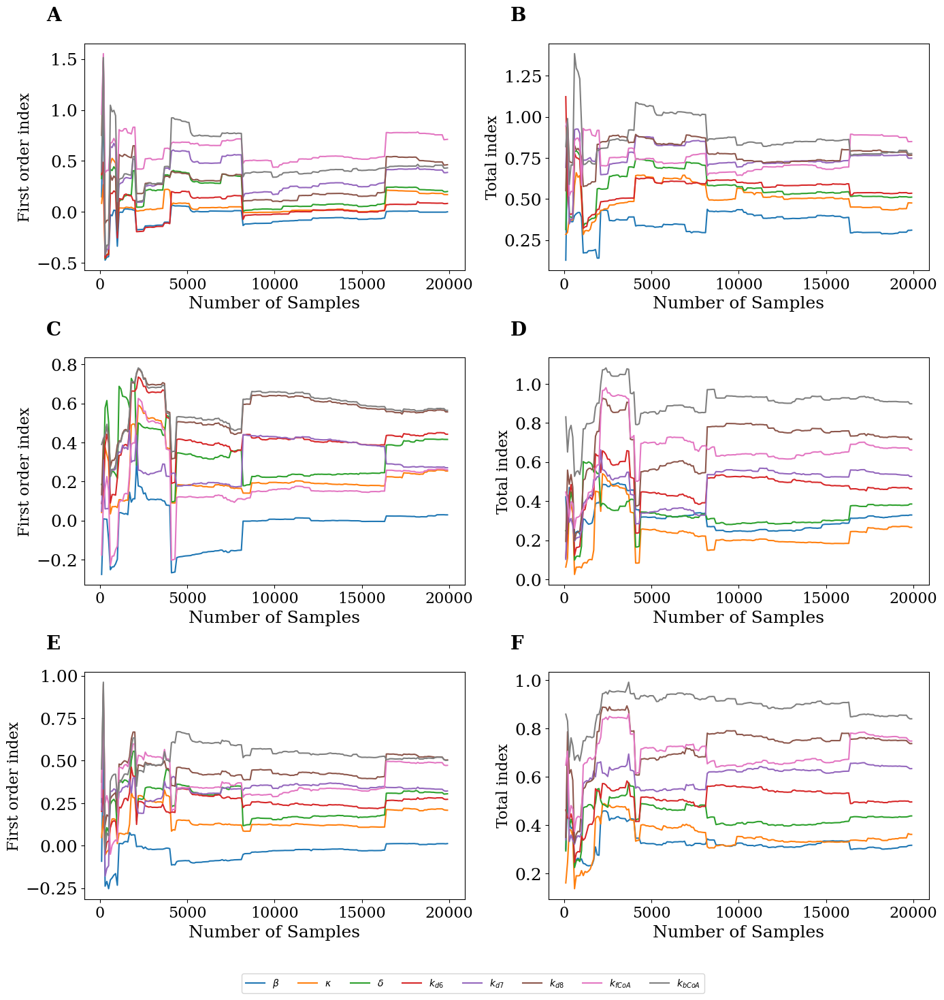

In [ ]:
fig, axs = plt.subplots(3,2,  figsize=(14,14))
axes = axs.flat
for i in range(8):
    axs[0,0].plot(nsamples,S1_estimatesC14[i] )
    axs[0,1].plot(nsamples,ST_estimatesC14[i] )
    axs[1,0].plot(nsamples,S1_estimatesC16[i] )
    axs[1,1].plot(nsamples,ST_estimatesC16[i] )
    axs[2,0].plot(nsamples,S1_estimatesC18[i] )
    axs[2,1].plot(nsamples,ST_estimatesC18[i] )
  
    
    
    
axs[0,0].tick_params(axis="x", labelsize=16)
axs[0,1].tick_params(axis="x", labelsize=16)
axs[1,0].tick_params(axis="x", labelsize=16)
axs[1,1].tick_params(axis="x", labelsize=16)
axs[2,0].tick_params(axis="x", labelsize=16)
axs[2,1].tick_params(axis="x", labelsize=16)

axs[0,0].tick_params(axis="y", labelsize=16)
axs[0,1].tick_params(axis="y", labelsize=16)
axs[1,0].tick_params(axis="y", labelsize=16)
axs[1,1].tick_params(axis="y", labelsize=16)
axs[2,0].tick_params(axis="y", labelsize=16)
axs[2,1].tick_params(axis="y", labelsize=16)



for n , ax in enumerate(axes):
        ax.text(-0.1, 1.1, string.ascii_uppercase[n], transform=ax.transAxes, 
            size=20, weight='bold')
        ax.tick_params(axis="y", labelsize=18)
        ax.set_xlabel("Number of Samples", fontsize =18)

axs[0,0].set_ylabel("First order index", fontsize =16)
axs[0,1].set_ylabel("Total index", fontsize =16)
axs[1,0].set_ylabel("First order index", fontsize =16)
axs[1,1].set_ylabel("Total index", fontsize =16)
axs[2,0].set_ylabel("First order index", fontsize =16)
axs[2,1].set_ylabel("Total index", fontsize =16)

# axs[0,0].text(1, 1, 'C14:0', horizontalalignment='center', verticalalignment='center',)
# axs[0,1].text(0.9, 0.5, 'End text', horizontalalignment='center', verticalalignment='center',)

fig.legend(label_S1_ST, loc ="lower center", ncol = len(label_S1_ST), bbox_to_anchor=(0.5,-0.05))
fig.patch.set_alpha(0.0)
fig.tight_layout()
fig.savefig(RESULTS_DIR /"SA_sample_size.eps",  dpi =300,  bbox_inches='tight')
